# D59 TensorRT LLM Code run

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11

# TensorRT-LLM과 vLLM 비교 측정 구현 실습

## 오늘 확인할 문제

**다른 실행 엔진이 더 빠르다는 표를 받았을 때, 어떤 측정 조건을 확인해야 합니까?**

vLLM의 측정값을 다른 엔진의 성능표와 비교하려면 모델·GPU·입출력 길이·측정 방법이 같은지 확인해야 합니다. 오늘은 비교할 항목을 정하고 같은 측정 도구로 결과를 기록합니다. TensorRT-LLM으로 바꿀 때 얻을 성능과 설치·실행 준비에 드는 작업을 함께 검토합니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 모델·GPU·입출력·생성 설정을 대조해 비교 가능한 성능 결과를 고를 수 있다.
- [목표 2] 같은 측정기로 요청을 보내 첫 응답·요청별 평균 생성 시간·처리량을 기록할 수 있다.
- [목표 3] 실측과 모의값을 구분하고 성능 이득과 준비 비용을 근거로 엔진 교체를 판단할 수 있다.

오늘은 서빙 엔진 두 개를 **같은 조건으로 측정**하는 도구를 만듭니다. 측정 스크립트 하나로 vLLM과 TensorRT-LLM의 OpenAI 호환 서버를 같은 질문 파일과 같은 동시 요청 수로 측정하고 결과를 같은 열의 CSV로 남깁니다.

코랩 런타임에는 vLLM을 설치하므로 TensorRT-LLM을 같은 환경에 함께 설치할 수 없습니다(이론 노트 1.1절). 그래서 TensorRT-LLM 쪽 측정 행은 강사가 RunPod L4에서 같은 스크립트로 만들어 나눠 주고 여러분은 코랩 L4에서 vLLM 쪽 측정 행을 직접 만들어 강사의 CSV와 한 표에 놓습니다. 팀 선택 과제(Step 7 트랙 2)를 고른 팀은 RunPod 팀 Pod에서 두 엔진을 직접 측정합니다.

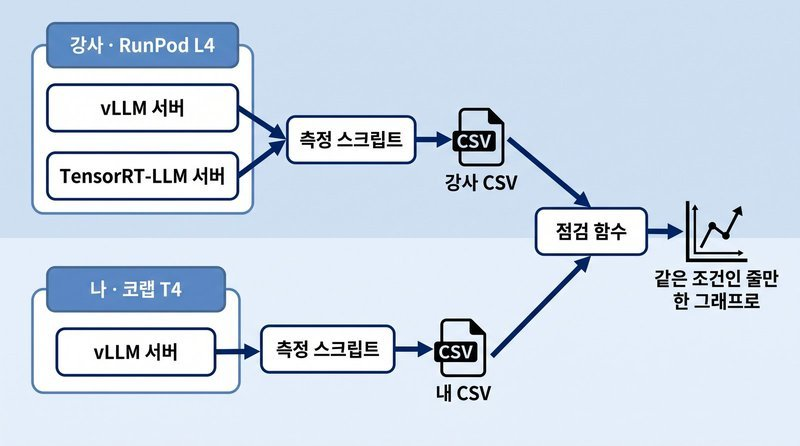

*엔진과 GPU가 달라도 측정 스크립트와 질문 파일은 하나이고 점검 함수를 통과한 행만 한 그래프에 놓습니다.*

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 실행 엔진의 차이와 비교 항목 | 90분 | 이론 1\~4장, Step 0\~2 |
| 측정 코드 작성과 모의 입력 검산 | 90분 | 이론 5장, Step 3\~4 |
| 직접 측정값과 외부 자료 구분 | 90분 | Step 5\~6 |
| 비교 조건 수정과 교체 판단 | 90분 | 이론 6장, Step 8 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

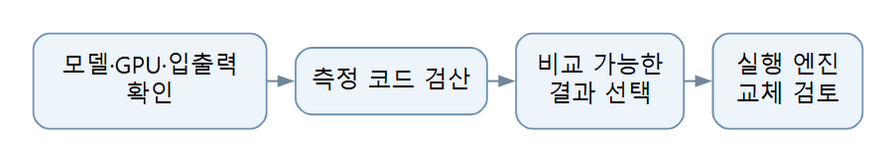

**실습 순서.** 모델·GPU·입출력 확인 → 측정 코드 검산 → 비교 가능한 결과 선택 → 실행 엔진 교체 검토 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| 엔진 빌드 |  실행할 장치와 조건에 맞게 모델의 계산 구성을 준비하는 과정 |
| 커널 융합 |  여러 연산을 한꺼번에 실행하도록 합치는 구현 |
| TTFT |  요청을 보낸 뒤 첫 출력 토큰을 받을 때까지 걸린 시간 |
| 인플라이트 배칭 |  진행 중인 생성 작업에 새 요청을 합류시키는 처리 방식 |

## 실행 환경

Step 5만 GPU가 필요하고 나머지 Step은 CPU 런타임에서도 실행됩니다.

| 항목 | 내용 |
|---|---|
| 런타임 | 코랩 L4 (24GB). T4에서도 실행되지만 강사 CSV와 GPU가 달라 다른 그룹으로 나뉩니다 |
| 로드하는 모델 | Qwen2.5-1.5B-Instruct (Step 5에서 vLLM으로 한 번) |
| 다운로드하는 것 | vLLM 0.30 wheel 파일 약 315MB와 의존성, 모델 3.1GB |
| 강사가 미리 해 오는 것 |  RunPod L4에서 두 엔진으로 측정한 `d59_bench_instructor.csv`, `d59_quality_instructor.csv` |
| 팀 선택 과제 |  Step 7 트랙 2. 56·57일차 팀 Pod와 볼륨에서 한두 시간, 팀마다 한 명이 실행하고 나머지는 검토 |
| 서버 포트 | 8590부터 비어 있는 것 |

| 오래 걸리는 셀 | 하는 일 | 대략 (T4 기준 추정, L4는 같거나 짧음) |
|---|---|---|
| Step 0 설치 | 가벼운 패키지 셋 | 1분 안팎 |
| Step 5 설치 | vLLM 0.30과 PyTorch 2.13 | 3\~6분, 끝나면 세션 다시 시작 |
| Step 5 서버 기동 | 모델 다운로드, 컴파일, CUDA 그래프 캡처 | 3\~8분 |
| Step 5 측정 | 동시 요청 1\~32, 요청 270개 남짓 | 5\~10분 |
| 부록 실습 B 컴파일 | 작은 블록의 첫 컴파일 | 1분 안팎 |

**로컬 작업** 표시가 붙은 곳은 RunPod이나 사내 GPU 서버에서 하는 일입니다. `.sh` 스크립트와 그 명령은 여러분의 PC가 아니라 파드(리눅스) 터미널에서 실행합니다. 코랩에서는 읽고 넘어가도 되고 강사가 미리 해 와서 결과 파일로 나눠 줍니다. 트랙 2를 고른 팀은 직접 실행합니다.

## Step 0. 환경 준비

버전을 고정합니다.

In [1]:
# Step 5에서 vLLM을 설치하면 FastAPI는 vLLM이 고른 버전(>=0.133,<0.137)으로 바뀝니다. 버전 정본의 예외이며 그 뒤에는 이 셀을 다시 실행하지 않습니다
!pip install -q "httpx>=0.28,<1" "fastapi>=0.141,<0.142" "uvicorn[standard]>=0.53,<0.54"
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv, json, os, re, socket, subprocess, sys, time
from collections import Counter
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError


def pkgver(dist):
    """배포판 이름으로 설치된 버전을 읽습니다"""
    try:
        return version(dist)
    except PackageNotFoundError:
        return "미설치"


print("[설치된 버전]", {d: pkgver(d) for d in ["httpx", "fastapi", "uvicorn", "torch", "vllm", "tensorrt-llm"]})

[설치된 버전] {'httpx': '0.28.1', 'fastapi': '0.141.1', 'uvicorn': '0.53.0', 'torch': '2.13.0', 'vllm': '0.30.0', 'tensorrt-llm': '미설치'}


In [3]:
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    HAS_GPU = False

if HAS_GPU:
    GPU_NAME = torch.cuda.get_device_name(0)
    CAP = torch.cuda.get_device_capability(0)
    GPU_CC = f"{CAP[0]}.{CAP[1]}"
    print(f"GPU : {GPU_NAME} / compute capability {GPU_CC}")
    print("TensorRT-LLM 지원 목록(Ampere 8.0부터, 이론 노트 1.1절) :", "안" if CAP[0] >= 8 else "밖")
else:
    GPU_NAME, GPU_CC = "", ""
    print("GPU 런타임이 아닙니다. Step 5를 빼고는 그대로 실행됩니다")

WORK = Path(os.environ.get("D59_WORK", "/content/d59"))
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
MODEL_ID = os.environ.get("D59_MODEL", "Qwen/Qwen2.5-1.5B-Instruct")
INSTRUCTOR_CSV = os.environ.get("D59_BENCH_CSV", str(WORK / "d59_bench_instructor.csv"))
INSTRUCTOR_QA = os.environ.get("D59_QUALITY_CSV", str(WORK / "d59_quality_instructor.csv"))
PORT_BASE = int(os.environ.get("D59_PORT_BASE", "8590"))
TARGET_TTFT_MS = float(os.environ.get("D59_TARGET_TTFT_MS", "2000"))   # SLO : p99 첫 토큰 시간
TARGET_TPOT_MS = float(os.environ.get("D59_TARGET_TPOT_MS", "100"))      # SLO : 요청별 평균 디코드 시간의 p99
print(f"작업 폴더 {WORK} / 모델 {MODEL_ID} / SLO 첫 토큰 {TARGET_TTFT_MS:.0f} ms, 토큰 사이 {TARGET_TPOT_MS:.0f} ms")


def pick_port(base=PORT_BASE, tries=10):
    """base 부터 비어 있는 포트를 찾습니다. 없으면 None"""
    for port in range(base, base + tries):
        with socket.socket() as probe:
            probe.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
            try:
                probe.bind(("127.0.0.1", port))
                return port
            except OSError:
                continue
    return None

GPU : NVIDIA A40 / compute capability 8.6
TensorRT-LLM 지원 목록(Ampere 8.0부터, 이론 노트 1.1절) : 안
작업 폴더 /content/d59 / 모델 Qwen/Qwen2.5-1.5B-Instruct / SLO 첫 토큰 2000 ms, 토큰 사이 100 ms


compute capability가 8.9로 출력되면 L4입니다. 7.5(T4)가 나오면 TensorRT-LLM 지원 목록 밖이고 Step 5의 측정 행은 강사 CSV와 다른 그룹으로 나뉩니다.

## Step 1. 질문 파일과 열 정의

교재 : 7.4.4 LLM 추론

강사와 여러분이 **같은 질문 파일**을 쓰도록 질문을 만드는 코드를 파일로 남깁니다.

In [4]:
%%writefile make_prompts.py
"""강사와 수강생이 같은 질문 파일을 만들도록 시드를 고정해 질문을 만듭니다.

  python make_prompts.py                         # d59_prompts.jsonl (긴 질문 30%)
  python make_prompts.py --long-ratio 0 --out d59_short.jsonl
"""
import argparse
import hashlib
import json
import random
from pathlib import Path

DEPTS = ["인사팀", "보안팀", "재무팀", "총무팀", "영업팀", "개발팀", "법무팀"]
TOPICS = ["재택근무", "연차", "출장비", "보안 사고", "법인카드", "교육", "회의실", "장비 반납"]
RULE = ("제{n}조({t}) {d}이 맡는 {t} 업무는 신청서를 받은 날부터 {k}일 안에 처리한다. "
        "처리 결과는 신청한 직원에게 메일로 알리고 처리 기록은 {y}년 동안 보관한다. ")


def make_prompts(n=600, long_ratio=0.3, seed=59):
    """짧은 문의와 규정 청크가 붙은 긴 질문을 섞습니다. 문의 번호가 달라 되풀이되지 않습니다"""
    rng = random.Random(seed)
    rows = []
    for i in range(n):
        t, d = rng.choice(TOPICS), rng.choice(DEPTS)
        q = f"[문의 {i:04d}] {d}에 {t} 관련해서 묻습니다. 신청하고 며칠 안에 처리되는지 두세 문장으로 알려 주세요."
        if rng.random() < long_ratio:
            k = rng.randint(14, 22)                      # 검색 결과가 붙은 RAG 질문
            rules = "".join(RULE.format(n=j + 1, t=rng.choice(TOPICS), d=rng.choice(DEPTS),
                                        k=rng.randint(2, 9), y=rng.randint(1, 5)) for j in range(k))
            q = f"다음 사내 규정을 읽고 답하십시오.\n규정 : {rules}\n질문 : {q}"
        rows.append({"id": i, "prompt": q})
    return rows


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--n", type=int, default=600)
    p.add_argument("--long-ratio", type=float, default=0.3)
    p.add_argument("--seed", type=int, default=59)
    p.add_argument("--out", default="d59_prompts.jsonl")
    a = p.parse_args()
    rows = make_prompts(a.n, a.long_ratio, a.seed)
    text = "\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n"
    Path(a.out).write_text(text, encoding="utf-8")
    sha = hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]
    print(f"저장 : {a.out} / 질문 {len(rows)}개 / 해시 {sha}")

Overwriting make_prompts.py


In [5]:
!python make_prompts.py

저장 : d59_prompts.jsonl / 질문 600개 / 해시 8df0816a0a74f397


In [6]:
prompt_rows = [json.loads(l) for l in Path("d59_prompts.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
lens = sorted(len(r["prompt"]) for r in prompt_rows)
print(f"질문 {len(prompt_rows)}개, 글자 수 중앙값 {lens[len(lens) // 2]}, 가장 긴 질문 {lens[-1]}자")
print("되풀이되는 질문 :", len(prompt_rows) - len({r["prompt"] for r in prompt_rows}), "개")

질문 600개, 글자 수 중앙값 63, 가장 긴 질문 2174자
되풀이되는 질문 : 0 개


되풀이되는 질문은 0개여야 합니다(이론 노트 5.3절). 두 엔진 모두 프리픽스 캐시가 켜져 있어서 같은 질문이 되풀이되면 엔진 대신 캐시 적중을 측정하게 됩니다.

In [7]:
COLUMN_GROUPS = {
    "엔진": ["engine", "engine_version", "server_cmd"],
    "환경": ["gpu", "gpu_cc", "kv_cache_tokens", "ready_s"],
    "모델": ["model", "model_revision", "precision"],
    "부하": ["prompt_file", "prompt_sha", "prompt_offset", "input_tokens_mean", "output_tokens", "ignore_eos",
             "gen_params", "concurrency", "num_requests", "warmup", "repeats"],
    "결과": ["ttft_p50_ms", "ttft_p99_ms", "tpot_p50_ms", "tpot_p99_ms", "e2e_p50_s", "e2e_p99_s",
             "output_tok_s", "req_s", "errors"],
    "기록": ["run_id", "measured_at", "source", "tool", "notes"],
}
REQUIRED = [c for cols in COLUMN_GROUPS.values() for c in cols]
TEXT_COLS = {"engine", "engine_version", "server_cmd", "gpu", "model", "model_revision", "precision", "prompt_file",
             "prompt_sha", "ignore_eos", "gen_params", "run_id", "measured_at", "source", "tool", "notes"}
NUMERIC = set(REQUIRED) - TEXT_COLS


def to_num(v):
    """빈 값은 0 이 아니라 None 으로 둡니다(0 은 '측정했는데 0'으로 읽힘)"""
    try:
        return float(v)
    except (TypeError, ValueError):
        return None


def load_bench_csv(path):
    """측정 CSV 를 읽습니다. 없거나 열이 모자라면 이유를 알리고 빈 목록"""
    p = Path(path)
    rows = list(csv.DictReader(p.open(encoding="utf-8"))) if p.exists() else []
    if not rows:
        print(f"CSV가 없거나 비어 있습니다 : {p}")
        return []
    missing = [c for c in REQUIRED if c not in rows[0]]
    if missing:
        print(f"열이 {len(missing)}개 모자랍니다 : {missing[:6]}")
        return []
    for r in rows:
        for c in NUMERIC:
            r[c] = to_num(r.get(c))
    return rows


print(COLUMN_GROUPS)

{'엔진': ['engine', 'engine_version', 'server_cmd'], '환경': ['gpu', 'gpu_cc', 'kv_cache_tokens', 'ready_s'], '모델': ['model', 'model_revision', 'precision'], '부하': ['prompt_file', 'prompt_sha', 'prompt_offset', 'input_tokens_mean', 'output_tokens', 'ignore_eos', 'gen_params', 'concurrency', 'num_requests', 'warmup', 'repeats'], '결과': ['ttft_p50_ms', 'ttft_p99_ms', 'tpot_p50_ms', 'tpot_p99_ms', 'e2e_p50_s', 'e2e_p99_s', 'output_tok_s', 'req_s', 'errors'], '기록': ['run_id', 'measured_at', 'source', 'tool', 'notes']}


In [8]:
instructor_rows = load_bench_csv(INSTRUCTOR_CSV)
if not instructor_rows:
    print("강사 CSV가 아직 없습니다. 강사가 나눠 준 파일을 작업 폴더에 업로드하거나 D59_BENCH_CSV 에 경로를 넣으세요")
    print("파일이 없어도 이 노트는 끝까지 실행됩니다. Step 6에서는 여러분의 측정 행만 그립니다")
else:
    print(f"강사 CSV {len(instructor_rows)}행 :", dict(Counter((r["engine"], r["gpu"]) for r in instructor_rows)))

강사 CSV 12행 : {('vllm', 'NVIDIA L4'): 6, ('tensorrt-llm', 'NVIDIA L4'): 6}


**강사 CSV를 지어내지 않습니다.**

## Step 2. 공정 비교 점검 함수

같은 동시 요청 수의 행끼리 **같아야 하는 열**을 비교하고 행마다 실측 여부, 예열, 요청 수, 질문의 되풀이를 봅니다. 조건 열만 다르게 만든 행으로 함수를 시험하는 셀은 부록 실습 H에 있습니다.

In [9]:
# 실습 : 엔진이 다른 두 행에서 값이 같아야 하는 열의 이름을 채우세요(COLUMN_GROUPS 에서, 엔진·결과 그룹은 빼고)
### START CODE HERE ### (두 엔진에 같게 둬야 하는 조건 열의 이름 목록 2줄)
# 1) 모델·리비전·정밀도, GPU, 질문 파일 해시와 꺼낸 위치, 출력 길이와 ignore_eos, 생성 설정, 예열, 요청 수, 측정 도구의 열
MUST_MATCH = ["model", "model_revision", "precision", "gpu", "prompt_sha", "prompt_offset",
              "output_tokens", "ignore_eos", "gen_params", "warmup", "num_requests", "tool"]
### END CODE HERE ###


def fairness_report(rows, must_match):
    """같은 동시 요청 수의 행끼리 조건이 같은지 봅니다. (문제 목록, 비교할 수 있는 행 번호)를 반환합니다"""
    if must_match is None:
        print("MUST_MATCH 가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
        return None, set()
    problems, ok_idx = [], set()
    for i, r in enumerate(rows):
        conc, nreq = r.get("concurrency"), r.get("num_requests")
        own = [msg for bad, msg in [
            (r.get("source") != "실측", f"source={r.get('source')} (실측이 아닌 행)"),
            (not r.get("warmup"), "예열 0"),
            (bool(conc) and nreq is not None and nreq < 4 * conc, "요청 수가 동시 요청 수의 네 배보다 적음"),
            (bool(r.get("repeats")), f"질문 되풀이 {r.get('repeats') or 0:.0f}번"),
            (bool(r.get("errors")), f"실패 {r.get('errors') or 0:.0f}건")] if bad]
        missing=[key for key in must_match if r.get(key) is None or r.get(key)==""]
        if missing:own.append("비교 조건 미확인: "+", ".join(missing))
        if r.get("output_tok_s") is None:own.append("실제 출력 토큰 수 미확인")
        if own:
            problems.append(f"행 {i} [{r.get('engine')} / 동시 {int(r.get('concurrency') or 0)}] " + ", ".join(own))
        else:
            ok_idx.add(i)
    by_conc = {}
    for i in ok_idx:
        by_conc.setdefault(rows[i].get("concurrency"), []).append(i)
    for conc, idx in sorted(by_conc.items(), key=lambda kv: kv[0] or 0):
        parts = {}
        for i in idx:
            parts.setdefault(tuple(str(rows[i].get(k)) for k in must_match), []).append(i)
        if len(parts) > 1:
            reps = [v[0] for v in parts.values()]
            diff = [k for k in must_match if len({str(rows[i].get(k)) for i in reps}) > 1]
            names = ", ".join(sorted(f"{rows[i].get('engine')}@{rows[i].get('gpu')}" for i in reps))
            problems.append(f"동시 {int(conc or 0)} : 조건이 다른 행이 섞여 있음 ({names}). 다른 열 {diff}")
        for v in parts.values():
            kv = [rows[i].get("kv_cache_tokens") for i in v if rows[i].get("kv_cache_tokens")]
            if len(kv) >= 2 and max(kv) > 1.2 * min(kv):
                problems.append(f"동시 {int(conc or 0)} : KV 캐시가 {int(min(kv))}~{int(max(kv))} 토큰으로 20% 넘게 다름 (메모리 비율 설정 확인)")
    return problems, ok_idx


def comparable_sets(rows, idx, must_match):
    """동시 요청 수마다 조건이 모두 같은 행의 그룹 가운데 엔진이 둘 이상인 그룹을 반환합니다"""
    out = {}
    for i in idx:
        r = rows[i]
        key = (r.get("concurrency"),) + tuple(str(r.get(k)) for k in must_match)
        out.setdefault(key, set()).add(r.get("engine"))
    return {int(k[0] or 0): sorted(v) for k, v in out.items() if len(v) >= 2}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
MUST_MATCH = ["model", "model_revision", "precision", "gpu", "prompt_sha", "prompt_offset",
              "output_tokens", "ignore_eos", "gen_params", "warmup", "num_requests", "tool"]
```

`kv_cache_tokens`는 넣지 않았습니다. 엔진마다 메모리를 세는 방식이 달라 똑같은 값이 나오기 어려우므로 같은지 대신 20% 넘게 다른지를 따로 봅니다(이론 노트 5.6절).

</details>

## Step 3. 측정 스크립트

측정 스크립트를 파일로 씁니다. httpx와 파이썬 표준 라이브러리만 쓰므로 어느 엔진의 이미지에서든 실행됩니다. RunPod에서 엔진을 기동하고 이 스크립트를 부르는 `serve_and_bench.sh`는 부록 실습 G에 있습니다.

**측정값의 정의**

오늘 기록하는 TPOT는 요청 하나의 첫 출력 뒤 경과 시간을 실제 출력 토큰 수로 나눈 평균입니다. `tpot_p99_ms`는 이 요청별 평균값의 p99이며, D58에서 청크 간격 표본으로 구한 ITL p99와 같은 지표가 아닙니다. 서버가 실제 토큰 수를 돌려주지 않으면 토큰 처리량과 TPOT는 미확인으로 둡니다. 이전 ITL 열 이름의 CSV와 자동으로 섞어 비교하지 않습니다.

In [10]:
%%writefile bench_openai.py
"""OpenAI 호환 서버 하나를 같은 조건으로 측정합니다. vLLM과 TensorRT-LLM에 똑같이 씁니다.

  python bench_openai.py --base-url URL --model M --engine vllm --precision fp16 --prompts d59_prompts.jsonl
동시 요청 수마다 한 행을 CSV에 더합니다. 지표 이름과 백분위는 vllm bench serve 와 맞춥니다.
"""
import argparse
import asyncio
import csv
import hashlib
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import httpx

TOOL = "bench_openai.py d59-2-tpot"

COLUMNS = [
    "run_id", "measured_at", "source", "engine", "engine_version", "server_cmd",
    "model", "model_revision", "precision", "gpu", "gpu_cc", "kv_cache_tokens", "ready_s",
    "prompt_file", "prompt_sha", "input_tokens_mean", "input_tokens_p95",
    "output_tokens", "ignore_eos", "gen_params",
    "concurrency", "num_requests", "warmup", "prompt_offset", "repeats",
    "ttft_p50_ms", "ttft_p99_ms", "tpot_p50_ms", "tpot_p99_ms", "e2e_p50_s", "e2e_p99_s",
    "output_tok_s", "req_s", "errors", "tool", "notes",
]
PASS_THROUGH = ["source", "engine", "engine_version", "server_cmd", "model", "model_revision", "precision", "gpu",
                "gpu_cc", "kv_cache_tokens", "ready_s", "output_tokens", "ignore_eos", "warmup", "notes"]


def percentile(values, q):
    """선형 보간 백분위. 값이 없으면 None"""
    xs = sorted(v for v in values if v is not None)
    if not xs:
        return None
    pos = (len(xs) - 1) * q / 100
    lo, hi = int(pos), min(int(pos) + 1, len(xs) - 1)
    return xs[lo] + (xs[hi] - xs[lo]) * (pos - lo)


def rnd(v, nd):
    return None if v is None else round(v, nd)


def pct(recs, key, q, scale, nd):
    return rnd(percentile([r[key] * scale for r in recs if r[key]], q), nd)


def load_prompts(path):
    raw = Path(path).read_bytes()
    prompts = [json.loads(line)["prompt"] for line in raw.decode("utf-8").splitlines() if line.strip()]
    return prompts, hashlib.sha256(raw).hexdigest()[:16]


async def one_request(client, url, model, prompt, gen):
    """요청 하나를 스트리밍으로 보내고 시각을 잽니다. 실패해도 예외를 내지 않습니다"""
    body = {"model": model, "stream": True, "stream_options": {"include_usage": True},
            "messages": [{"role": "user", "content": prompt}], **gen}
    rec = {"ok": False, "ttft": None, "e2e": None, "tpot": None, "out_tokens": 0, "in_tokens": None, "error": ""}
    t0 = time.perf_counter()
    t_first = t_last = None
    pieces = 0
    try:
        async with client.stream("POST", url, json=body) as r:
            if r.status_code != 200:
                rec["error"] = f"HTTP {r.status_code}"
                await r.aread()
                return rec
            async for line in r.aiter_lines():
                if not line.startswith("data:"):
                    continue
                data = line[5:].strip()
                if data == "[DONE]":
                    break
                chunk = json.loads(data)
                usage = chunk.get("usage")
                if usage:
                    rec["out_tokens"] = usage.get("completion_tokens") or rec["out_tokens"]
                    rec["in_tokens"] = usage.get("prompt_tokens")
                for ch in chunk.get("choices") or []:
                    if (ch.get("delta") or {}).get("content"):
                        t_last = time.perf_counter()
                        t_first = t_first or t_last
                        pieces += 1
    except (httpx.HTTPError, json.JSONDecodeError) as e:
        rec["error"] = type(e).__name__
        return rec
    if t_first is None:
        rec["error"] = "토큰 없음"
        return rec
    rec["usage_missing"] = not bool(rec["out_tokens"])  # 청크 수를 토큰 수로 대신하지 않습니다
    rec.update(ok=True, ttft=t_first - t0, e2e=t_last - t0)
    if rec["out_tokens"] > 1:
        rec["tpot"] = (t_last - t_first) / (rec["out_tokens"] - 1)
    return rec


async def run_level(client, url, model, prompts, conc, n, gen):
    sem = asyncio.Semaphore(conc)

    async def guarded(p):
        async with sem:
            return await one_request(client, url, model, p, gen)

    t0 = time.perf_counter()
    recs = await asyncio.gather(*(guarded(p) for p in prompts[:n]))
    return recs, time.perf_counter() - t0


async def main(a):
    prompts, sha = load_prompts(a.prompts)
    gen = {"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": a.seed,
           "max_tokens": a.output_tokens, "ignore_eos": a.ignore_eos}
    levels = [int(x) for x in a.concurrency.split(",") if x.strip()]
    url = a.base_url.rstrip("/") + "/v1/chat/completions"
    out = Path(a.out)
    new_file = not out.exists() or out.stat().st_size == 0
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + a.engine
    cursor, repeats_total = 0, 0

    def take(k):
        """질문을 차례로 꺼내고 모자라서 되풀이한 수를 셉니다"""
        nonlocal cursor, repeats_total
        picked = []
        for _ in range(k):
            repeats_total += cursor >= len(prompts)
            picked.append(prompts[cursor % len(prompts)])
            cursor += 1
        return picked

    limits = httpx.Limits(max_connections=max(levels) + 4, max_keepalive_connections=max(levels) + 4)
    async with httpx.AsyncClient(timeout=a.timeout, limits=limits) as client:
        with out.open("a", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=COLUMNS)
            if new_file:
                w.writeheader()
            for conc in levels:
                await run_level(client, url, a.model, take(a.warmup), conc, a.warmup, gen)   # 예열은 버립니다
                n = max(a.min_requests, a.per_conc * conc)
                before, offset = repeats_total, cursor
                recs, wall = await run_level(client, url, a.model, take(n), conc, n, gen)
                ok = [r for r in recs if r["ok"]]
                ins = [r["in_tokens"] for r in ok if r["in_tokens"] is not None]
                row = {k: getattr(a, k) for k in PASS_THROUGH}             # 인자를 그대로 옮기는 열
                row.update({
                    "run_id": run_id, "measured_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                    "prompt_file": Path(a.prompts).name, "prompt_sha": sha,
                    "input_tokens_mean": rnd(sum(ins) / len(ins), 1) if ins else None,
                    "input_tokens_p95": rnd(percentile(ins, 95), 1),
                    "gen_params": json.dumps(gen, sort_keys=True),
                    "concurrency": conc, "num_requests": n, "prompt_offset": offset,
                    "repeats": repeats_total - before,
                    "ttft_p50_ms": pct(ok, "ttft", 50, 1000, 1), "ttft_p99_ms": pct(ok, "ttft", 99, 1000, 1),
                    "tpot_p50_ms": pct(ok, "tpot", 50, 1000, 2), "tpot_p99_ms": pct(ok, "tpot", 99, 1000, 2),
                    "e2e_p50_s": pct(ok, "e2e", 50, 1, 3), "e2e_p99_s": pct(ok, "e2e", 99, 1, 3),
                    "output_tok_s": rnd(sum(r["out_tokens"] for r in ok) / wall, 1) if wall > 0 and all(not r.get("usage_missing") for r in ok) else None,
                    "req_s": rnd(len(ok) / wall, 3) if wall > 0 else None,
                    "errors": len(recs) - len(ok), "tool": TOOL,
                })
                w.writerow(row)
                f.flush()
                first_err = next((r["error"] for r in recs if not r["ok"]), "")
                print(f"동시 {conc:>3} | 요청 {n:>4} | 첫 토큰 p50 {row['ttft_p50_ms']} ms, p99 {row['ttft_p99_ms']} ms"
                      f" | 초당 출력 토큰 {row['output_tok_s']} | 실패 {row['errors']} {first_err}")
    if repeats_total:
        print(f"주의 : 질문이 {repeats_total}번 되풀이되었습니다. 프리픽스 캐시 적중이 섞입니다. 질문 파일을 늘리세요")
    if a.source != "실측":
        print(f"주의 : source={a.source} 인 행입니다. 엔진 비교에 쓰지 않습니다")
    print(f"저장 : {out} (run_id {run_id})")


def parse(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    for name in ["--base-url", "--model", "--engine", "--precision", "--prompts"]:
        p.add_argument(name, required=True)              # --engine 은 vllm 또는 tensorrt-llm
    for name in ["--engine-version", "--server-cmd", "--model-revision", "--gpu", "--gpu-cc",
                 "--kv-cache-tokens", "--ready-s", "--notes"]:
        p.add_argument(name, default="")                 # 서버 로그·/metrics 에서 읽은 값과 기록용 값
    p.add_argument("--concurrency", default="1,2,4,8,16")
    p.add_argument("--min-requests", type=int, default=16)
    p.add_argument("--per-conc", type=int, default=4, help="동시 요청 수의 몇 배를 보낼지")
    p.add_argument("--warmup", type=int, default=4)
    p.add_argument("--output-tokens", type=int, default=128, help="vLLM 심화 노트의 부하 테스트와 같은 128")
    p.add_argument("--no-ignore-eos", dest="ignore_eos", action="store_false")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--timeout", type=float, default=600)
    p.add_argument("--source", default="실측", help="실측 또는 대역")
    p.add_argument("--out", default="d59_bench.csv")
    return p.parse_args(argv)


if __name__ == "__main__":
    args = parse()
    if args.warmup < 1:
        print("예열 요청이 0개입니다. 서버를 기동한 직후의 준비 시간이 섞이므로 1 이상을 주세요")
        sys.exit(2)
    asyncio.run(main(args))

Overwriting bench_openai.py


## Step 4. mock 서버를 이용한 측정 스크립트 테스트

벤치마크 하네스부터 테스트합니다. 모델을 로드하는 데는 몇 분이 걸리지만 측정 스크립트의 버그는 mock 서버로 몇 초 만에 찾습니다.

In [11]:
%%writefile fake_engine.py
# mock 엔진 : 연속 배칭을 흉내 내는 OpenAI 호환 서버. 측정값은 어느 엔진의 성능도 아닙니다
import asyncio
import json
import os
import uuid
from contextlib import asynccontextmanager

from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse, StreamingResponse

STEP_MS = float(os.environ.get("FAKE_STEP_MS", "15"))          # 배치 하나를 한 번 계산하는 바탕 시간
PER_SEQ_MS = float(os.environ.get("FAKE_PER_SEQ_MS", "1.5"))   # 요청 하나당 더해지는 시간
PREFILL_MS_PER_100 = float(os.environ.get("FAKE_PREFILL_MS_PER_100", "4"))  # 질문 100글자의 프리필 시간
MAX_SEQS = int(os.environ.get("FAKE_MAX_SEQS", "8"))
MODEL_NAME = os.environ.get("FAKE_MODEL", "stub-model")
waiting: asyncio.Queue | None = None


class Seq:
    def __init__(self, prompt_chars, max_tokens, ignore_eos):
        self.prompt_chars, self.made, self.out = prompt_chars, 0, asyncio.Queue()
        self.stop_at = max_tokens if ignore_eos else min(max_tokens, 12)


async def scheduler():
    active = []
    while True:
        new = []
        while len(active) + len(new) < MAX_SEQS and not waiting.empty():
            new.append(waiting.get_nowait())
        if not active and not new:
            new.append(await waiting.get())
        prefill = sum(s.prompt_chars for s in new) / 100 * PREFILL_MS_PER_100
        active += new
        await asyncio.sleep((STEP_MS + PER_SEQ_MS * len(active) + prefill) / 1000)
        for s in active:
            s.made += 1
            await s.out.put("토큰 ")
        for s in [s for s in active if s.made >= s.stop_at]:
            await s.out.put(None)
            active.remove(s)


@asynccontextmanager
async def lifespan(app):
    # 비동기 처리 노트 7.2절의 lifespan 그대로입니다
    global waiting
    waiting = asyncio.Queue()
    task = asyncio.create_task(scheduler())
    yield
    task.cancel()


app = FastAPI(lifespan=lifespan)


@app.get("/health")
async def health():
    return {"status": "ok"}


@app.post("/v1/chat/completions")
async def chat(request: Request):
    body = await request.json()
    text = "".join(m.get("content", "") for m in body.get("messages", []))
    seq = Seq(len(text), int(body.get("max_tokens") or 16), bool(body.get("ignore_eos", False)))
    await waiting.put(seq)
    rid, ptok = "chatcmpl-" + uuid.uuid4().hex[:12], max(1, len(text) // 2)

    def usage():
        return {"prompt_tokens": ptok, "completion_tokens": seq.made, "total_tokens": ptok + seq.made}

    if not body.get("stream"):   # 부록 실습 A의 평가 하네스가 쓰는 스트리밍 없는 응답
        parts = []
        while (piece := await seq.out.get()) is not None:
            parts.append(piece)
        msg = {"role": "assistant", "content": "mock 서버의 답입니다. " + "".join(parts)}
        return JSONResponse({"id": rid, "object": "chat.completion", "model": MODEL_NAME, "usage": usage(),
                             "choices": [{"index": 0, "finish_reason": "length", "message": msg}]})

    def sse(choices, **extra):
        chunk = {"id": rid, "object": "chat.completion.chunk", "model": MODEL_NAME, "choices": choices, **extra}
        return f"data: {json.dumps(chunk, ensure_ascii=False)}\n\n"

    async def events():
        yield sse([{"index": 0, "delta": {"role": "assistant", "content": ""}}])
        while (piece := await seq.out.get()) is not None:
            yield sse([{"index": 0, "delta": {"content": piece}}])
        if (body.get("stream_options") or {}).get("include_usage"):
            yield sse([], usage=usage())
        yield "data: [DONE]\n\n"

    return StreamingResponse(events(), media_type="text/event-stream")

Overwriting fake_engine.py


In [12]:
import httpx


def start_server(cmd, port, log_name, timeout=900, health="/health"):
    """서버를 기동하고 준비될 때까지 기다립니다. 실패하면 (None, 이유, None)"""
    log = open(log_name, "w")
    t0 = time.perf_counter()
    proc = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT)
    url = f"http://127.0.0.1:{port}{health}"
    while time.perf_counter() - t0 < timeout:
        if proc.poll() is not None:
            return None, f"서버가 멈췄습니다(코드 {proc.returncode}). {log_name}의 끝부분을 보세요", None
        try:
            if httpx.get(url, timeout=2).status_code == 200:
                return proc, "준비됨", round(time.perf_counter() - t0, 1)
        except httpx.HTTPError:
            pass
        time.sleep(1)
    proc.terminate()
    return None, f"{timeout}초 안에 준비되지 않았습니다", None


def run_bench(port, model, engine, out, *args, fresh=True):
    """bench_openai.py 로 측정하고 out CSV 를 읽어 반환합니다"""
    if fresh:
        Path(out).unlink(missing_ok=True)
    r = subprocess.run([sys.executable, "bench_openai.py", "--base-url", f"http://127.0.0.1:{port}", "--model", model,
                        "--engine", engine, "--prompts", "d59_prompts.jsonl", "--out", out, *map(str, args)],
                       capture_output=True, text=True)
    print(r.stdout[-2500:] or r.stderr[-2500:])
    return load_bench_csv(out)


def stop_server(proc):
    """서버를 종료합니다(이미 종료되었으면 그냥 둠)"""
    if proc is not None and proc.poll() is None:
        proc.terminate()
        try:
            proc.wait(timeout=30)
        except subprocess.TimeoutExpired:
            proc.kill()

In [13]:
STUB_PORT = pick_port()
stub_proc, why, stub_ready = (start_server([sys.executable, "-m", "uvicorn", "fake_engine:app", "--port", str(STUB_PORT),
                                            "--log-level", "warning"], STUB_PORT, "stub_server.log", timeout=60)
                              if STUB_PORT else (None, "8590부터 포트가 모두 차 있습니다", None))
print(f"mock 서버 : {why} (포트 {STUB_PORT}, 준비 {stub_ready}초)")

mock 서버 : 준비됨 (포트 8590, 준비 1.1초)


In [14]:
stub_rows = []
if stub_proc is not None:
    stub_rows = run_bench(STUB_PORT, "stub-model", "stub", "d59_stub.csv", "--precision", "fp16",
                          "--concurrency", "1,4,8", "--min-requests", 8, "--warmup", 2, "--output-tokens", 16,
                          "--ready-s", stub_ready, "--source", "대역")

동시   1 | 요청    8 | 첫 토큰 p50 24.6 ms, p99 94.0 ms | 초당 출력 토큰 55.4 | 실패 0 
동시   4 | 요청   16 | 첫 토큰 p50 105.1 ms, p99 218.5 ms | 초당 출력 토큰 137.8 | 실패 0 
동시   8 | 요청   32 | 첫 토큰 p50 285.6 ms, p99 406.1 ms | 초당 출력 토큰 181.2 | 실패 0 
주의 : source=대역 인 행입니다. 엔진 비교에 쓰지 않습니다
저장 : d59_stub.csv (run_id 20261113T080344Z-stub)



**눈여겨볼 곳** : 동시 요청 수를 늘리면 첫 토큰 시간의 p99가 커지고 초당 출력 토큰은 늘다가 덜 늘어납니다.

In [15]:
problems, ok_idx = fairness_report(stub_rows, MUST_MATCH)
if problems is not None:
    print("\n".join(problems[:5]) or "문제 없음")
    print("판단에 쓸 수 있는 행 :", sorted(ok_idx) or "없음")
stop_server(stub_proc)   # 부록 실습 A가 필요하면 다시 기동합니다
print("mock 서버를 종료했습니다")

행 0 [stub / 동시 1] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
행 1 [stub / 동시 4] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
행 2 [stub / 동시 8] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
판단에 쓸 수 있는 행 : 없음
mock 서버를 종료했습니다


## Step 5. L4에서 vLLM 측정

vLLM 0.30을 설치하고 Qwen2.5-1.5B-Instruct를 L4에 로드해 Step 3의 측정 스크립트로 측정합니다.

서버를 기동하는 인자는 강사가 RunPod L4에서 쓴 `serve_and_bench.sh`(부록 실습 G)의 vLLM 쪽과 같습니다.

In [16]:
# GPU 런타임에서만. vLLM 0.30.0은 torch 2.13.0을 요구해 코랩의 PyTorch를 바꿉니다
# 설치가 끝나면 [런타임] - [세션 다시 시작] 뒤 Step 0의 두 번째 셀부터 다시 실행하세요
!pip install --ignore-installed PyJWT "vllm>=0.30,<0.31"

  Using cached pyjwt-2.15.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached vllm-0.30.0-cp38-abi3-manylinux_2_28_x86_64.whl.metadata (11 kB)
  Using cached regex-2026.11.9-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached cachetools-8.0.0-py3-none-any.whl.metadata (5.6 kB)
  Using cached psutil-7.2.2-cp36-abi3-manylinux2010_x86_64.manylinux_2_12_x86_64.manylinux_2_28_x86_64.whl.metadata (22 kB)
  Using cached sentencepiece-0.2.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (34 kB)
  Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached blake3-1.0.11-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.9 kB)
  Using cached py_cpuinfo-9.0.0-py3-none-any.whl.metadata (794 bytes)
  Using cached tr

In [17]:
VLLM_PORT, vllm_proc, vllm_ready, VLLM_KV, ATTN = None, None, None, None, None
VLLM_CMD = []
if not HAS_GPU:
    print("GPU 런타임이 아닙니다. 강사 CSV와 mock 행으로 Step 6까지 갑니다")
elif pkgver("vllm") == "미설치":
    print("vLLM이 없습니다. 설치 셀을 실행하고 세션을 다시 시작하세요")
else:
    from huggingface_hub import snapshot_download
    MODEL_SNAPSHOT=Path(snapshot_download(MODEL_ID))
    MODEL_REVISION=MODEL_SNAPSHOT.name
    VLLM_PORT = pick_port(PORT_BASE + 1)
    # 강사 CSV와 같은 fp16(half)으로 맞춥니다. T4 라면 bf16 계산이 없어 이 값이어야 합니다(D53 이론 2.1절)
    VLLM_CMD = ["vllm", "serve", str(MODEL_SNAPSHOT), "--served-model-name", MODEL_ID, "--dtype", "half", "--max-model-len", "4096",
                "--gpu-memory-utilization", "0.85", "--max-num-seqs", "128", "--max-num-batched-tokens", "8192",
                "--enable-chunked-prefill", "--generation-config", "vllm", "--seed", "0",
                "--host", "127.0.0.1", "--port", str(VLLM_PORT)]
    vllm_proc, why, vllm_ready = start_server(VLLM_CMD, VLLM_PORT, "vllm_server.log", timeout=1200)
    print(f"vLLM 서버 : {why} (준비 {vllm_ready}초)")
    log = Path("vllm_server.log").read_text(encoding="utf-8", errors="ignore")
    m, a = re.search(r"GPU KV cache size: ([\d,]+) tokens", log), re.search(r"Using (\S+) attention backend", log)
    VLLM_KV, ATTN = (int(m.group(1).replace(",", "")) if m else None), (a.group(1) if a else None)
    print("KV 캐시 토큰 :", VLLM_KV, "/ 어텐션 백엔드 :", ATTN, "(None 이면 vllm_server.log 를 직접 봅니다)")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

vLLM 서버 : 준비됨 (준비 117.2초)
KV 캐시 토큰 : 1267792 / 어텐션 백엔드 : FLASH_ATTN (None 이면 vllm_server.log 를 직접 봅니다)


**받을 준비를 마친 시간**이 출력되었는지 봅니다.

In [18]:
my_rows = []
if vllm_proc is not None:
    my_rows = run_bench(VLLM_PORT, MODEL_ID, "vllm", "d59_bench_mine.csv", "--engine-version", pkgver("vllm"),
                        "--server-cmd", " ".join(VLLM_CMD), "--model-revision", MODEL_REVISION, "--precision", "fp16", "--gpu", GPU_NAME,
                        "--gpu-cc", GPU_CC, "--kv-cache-tokens", VLLM_KV or "", "--ready-s", vllm_ready,
                        "--concurrency", "1,2,4,8,16,32", "--notes", f"attention={ATTN}, chunked_prefill=on")

동시   1 | 요청   16 | 첫 토큰 p50 41.2 ms, p99 74.2 ms | 초당 출력 토큰 138.6 | 실패 0 
동시   2 | 요청   16 | 첫 토큰 p50 66.4 ms, p99 116.5 ms | 초당 출력 토큰 266.1 | 실패 0 
동시   4 | 요청   16 | 첫 토큰 p50 121.5 ms, p99 159.2 ms | 초당 출력 토큰 496.1 | 실패 0 
동시   8 | 요청   32 | 첫 토큰 p50 134.5 ms, p99 213.5 ms | 초당 출력 토큰 944.5 | 실패 0 
동시  16 | 요청   64 | 첫 토큰 p50 213.8 ms, p99 294.5 ms | 초당 출력 토큰 1687.0 | 실패 0 
동시  32 | 요청  128 | 첫 토큰 p50 402.2 ms, p99 620.5 ms | 초당 출력 토큰 2655.6 | 실패 0 
저장 : d59_bench_mine.csv (run_id 20261113T080809Z-vllm)



## Step 6. 한 표에 모은 측정 결과 해석

교재 : 2.4.2 확장성

강사 CSV, 여러분의 CSV, mock CSV를 모아 점검 함수로 거릅니다. 점검을 통과한 행을 조건이 같은 그룹으로 나눠 그룹마다 표와 그래프를 하나씩 만듭니다.

In [19]:
all_rows = instructor_rows + my_rows + stub_rows
print(f"강사 {len(instructor_rows)}행, 내 측정 {len(my_rows)}행, mock {len(stub_rows)}행")
problems, ok_idx = fairness_report(all_rows, MUST_MATCH)
if problems is not None:
    print("\n".join(" - " + p for p in problems[:12]), f"(문제 {len(problems)}개)")
    print("같은 조건으로 비교할 수 있는 엔진 :", comparable_sets(all_rows, ok_idx, MUST_MATCH) or "없음")

강사 12행, 내 측정 6행, mock 3행
 - 행 18 [stub / 동시 1] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
 - 행 19 [stub / 동시 4] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
 - 행 20 [stub / 동시 8] source=대역 (실측이 아닌 행), 비교 조건 미확인: model_revision, gpu
 - 동시 1 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu']
 - 동시 2 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu']
 - 동시 4 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu']
 - 동시 8 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu']
 - 동시 16 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu']
 - 동시 32 : 조건이 다른 행이 섞여 있음 (vllm@NVIDIA A40, vllm@NVIDIA L4). 다른 열 ['gpu'] (문제 9개)
같은 조건으로 비교할 수 있는 엔진 : {1: ['tensorrt-llm', 'vllm'], 2: ['tensorrt-llm', 'vllm'], 4: ['tensorrt-llm', 'vllm'], 8: ['tensorrt-llm', 'vllm'], 16: ['tensorrt-llm', 'vllm'], 32: ['tensorrt-llm', 'vllm']}


**비교에서 제외된 측정 행과 제외 이유를 확인합니다.** mock 행은 실측이 아니라서 빠집니다. 강사 CSV 안의 두 엔진은 같은 L4에서 같은 조건으로 측정했으므로 같은 그룹으로 나오고 그 그룹이 오늘의 엔진 비교입니다. 여러분의 L4 vLLM 행도 조건이 같으면 그 그룹에 들어가 강사의 vLLM 행과 나란히 그려지고 두 vLLM 곡선이 가까운지가 측정을 재현했는지의 확인입니다. T4에서 측정했다면 `gpu`가 달라 다른 그룹으로 나옵니다.

In [20]:
# 동시 요청 수마다 달라지는 열을 뺀 조건이 모두 같은 행끼리 한 그룹으로 모읍니다
# 그룹 안에서는 측정 한 번(run_id)마다 선 하나를 그려 강사와 여러분의 vLLM 행이 섞이지 않게 합니다
RUN_KEYS = [k for k in (MUST_MATCH or []) if k not in ("prompt_offset", "num_requests")]
cond_groups = {}
for i in sorted(ok_idx):
    r = all_rows[i]
    key = tuple(str(r.get(k)) for k in RUN_KEYS)
    cond_groups.setdefault(key, {}).setdefault(r.get("run_id") or r["engine"], []).append(r)
print(f"조건 그룹 {len(cond_groups)}개 :", [sorted(g) for g in cond_groups.values()] or "없음 (강사 CSV나 Step 5의 측정 행이 필요합니다)")
print("그룹별 숫자 표는 부록 실습 F에서 출력합니다")

조건 그룹 2개 : [['20261105T041000Z-vllm', '20261105T043000Z-tensorrt-llm'], ['20261113T080809Z-vllm']]
그룹별 숫자 표는 부록 실습 F에서 출력합니다


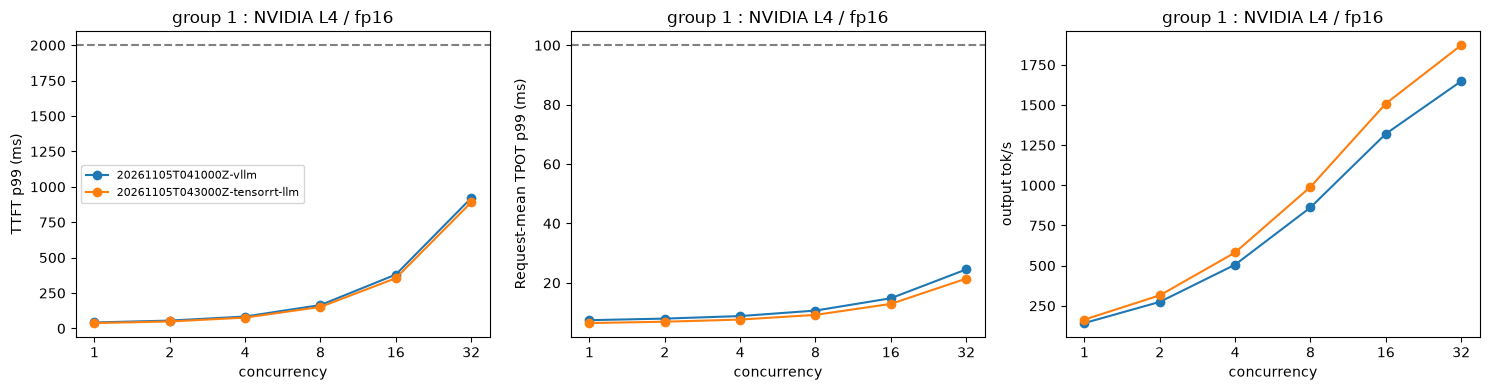

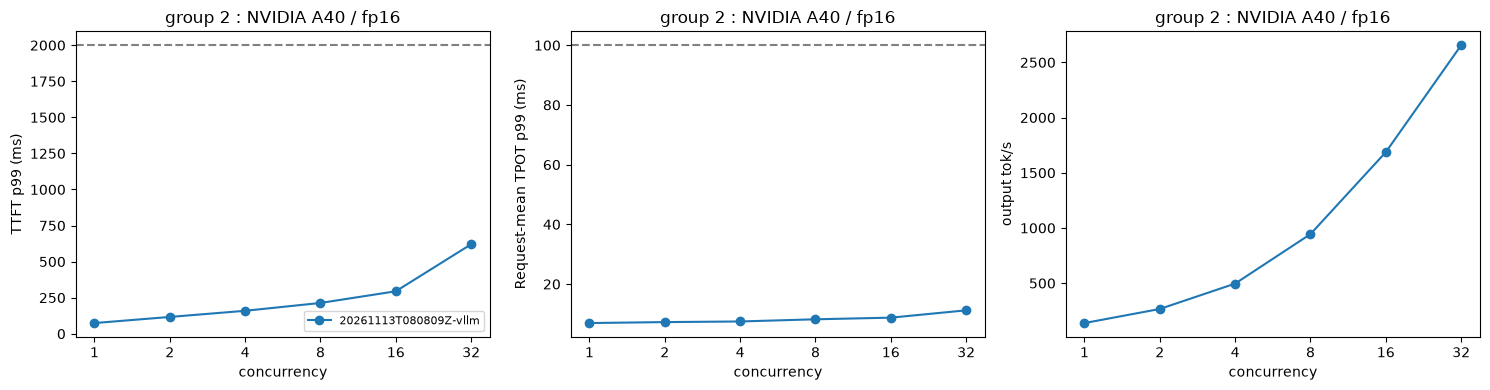

In [21]:
import matplotlib.pyplot as plt

for n, (key, by_engine) in enumerate(cond_groups.items(), 1):
    some = next(iter(by_engine.values()))[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    xs_all = sorted({r["concurrency"] for rs in by_engine.values() for r in rs})
    for eng, rs in sorted(by_engine.items()):
        rs = sorted(rs, key=lambda r: r["concurrency"])
        for ax, col in zip(axes, ["ttft_p99_ms", "tpot_p99_ms", "output_tok_s"]):
            ax.plot([r["concurrency"] for r in rs], [r[col] for r in rs], marker="o", label=eng)
    for ax, slo, yl in zip(axes, [TARGET_TTFT_MS, TARGET_TPOT_MS, None], ["TTFT p99 (ms)", "Request-mean TPOT p99 (ms)", "output tok/s"]):
        if slo:
            ax.axhline(slo, linestyle="--", color="gray")    # 점선이 SLO
        ax.set_xscale("log", base=2)
        ax.set(ylabel=yl, title=f"group {n} : {some['gpu']} / {some['precision']}")
        ax.set(xticks=xs_all, xticklabels=[int(x) for x in xs_all], xlabel="concurrency")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"d59_curves_{n}.png", dpi=120)
    plt.show()
if not cond_groups:
    print("그릴 행이 없습니다")

**그래프를 읽는 순서**

1. 첫 토큰 시간과 토큰 사이 간격 그래프에서 점선(SLO)을 넘는 동시 요청 수를 엔진마다 찾습니다  
2. 그 언저리에서 곡선이 꺾이는지 봅니다. 꺾이는 지점이 그 설정에서 엔진이 받아 내는 한계입니다(이론 노트 5.7절)  
3. 처리량 그래프에서 같은 동시 요청 수의 두 엔진을 비교합니다. 처리량이 앞선 쪽이 첫 토큰 시간에서도 앞서는지 따로 봅니다

In [22]:
# 실습 : 두 p99 가 모두 SLO 이하이고 실패가 0 인 행의 concurrency 가운데 가장 큰 값을 찾으세요(None 은 불만족)
def max_concurrency_within(rs, ttft_ms, itl_ms):
    ### START CODE HERE ### (SLO를 만족한 행의 concurrency 목록 4줄)
    # 1) 두 p99 가 값이 있고 SLO 이하이며 실패가 0 인 행의 concurrency
    ok = [r["concurrency"] for r in rs
          if r["ttft_p99_ms"] is not None and r["ttft_p99_ms"] <= ttft_ms
          and r["tpot_p99_ms"] is not None and r["tpot_p99_ms"] <= itl_ms
          and r["errors"] == 0]
    ### END CODE HERE ###
    if ok is None:
        return "빈칸"
    return max(ok) if ok else None


for n, by_engine in enumerate(cond_groups.values(), 1):
    for eng, rs in sorted(by_engine.items()):
        m = max_concurrency_within(rs, TARGET_TTFT_MS, TARGET_TPOT_MS)
        print(f"[조건 그룹 {n}] {eng:<24} SLO 만족 :", "빈칸을 채우세요" if m == "빈칸"
              else f"동시 요청 {int(m)}개까지" if m else "측정 범위에서 만족하지 못함")

[조건 그룹 1] 20261105T041000Z-vllm    SLO 만족 : 동시 요청 32개까지
[조건 그룹 1] 20261105T043000Z-tensorrt-llm SLO 만족 : 동시 요청 32개까지
[조건 그룹 2] 20261113T080809Z-vllm    SLO 만족 : 동시 요청 32개까지


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
ok = [r["concurrency"] for r in rs
      if r["ttft_p99_ms"] is not None and r["ttft_p99_ms"] <= ttft_ms
      and r["tpot_p99_ms"] is not None and r["tpot_p99_ms"] <= itl_ms
      and r["errors"] == 0]
```

**p99로 셉니다.** 중앙값으로 세면 요청의 절반이 SLO를 넘어도 통과로 셉니다(이론 노트 5.4절).

</details>

In [23]:
stop_server(vllm_proc)
print("vLLM 서버를 종료했습니다")

vLLM 서버를 종료했습니다


## Step 7. 선택 심화 트랙

트랙 1은 각자 코랩 GPU 런타임에서 하고 트랙 2는 팀이 고를 때만  RunPod 팀 Pod에서 하는 팀 선택 과제입니다. 생성 설정 기본값의 함정, 입력 길이 분포별 측정, 옛 엔진 빌드 절차는 부록 실습 C\~E에 있습니다.

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | FP8과 다른 GPU에서 다시 측정 | 측정 | 중 |
| 2 |  팀 선택 과제 : RunPod에서 TensorRT-LLM 1.2 직접 측정 | 측정 | 상 |

#### 트랙 1. FP8과 다른 GPU에서 다시 측정

Step 5의 vLLM 서버와 같은 설정에 `--quantization fp8`만 더해 FP8 측정 행을 만듭니다. L4는 FP8 계산을 지원하는 Ada Lovelace 세대입니다(이론 노트 4.1절).

코랩 Pro+에서 A100 런타임을 고를 수 있다면 Step 0부터 Step 5까지 같은 코드로 fp16 행을 다시 측정해 GPU만 다른 그룹을 만듭니다. A100에는 FP8 계산이 없어 아래 셀은 건너뜁니다.

In [24]:
# 트랙 1 : FP8 은 compute capability 8.9 이상(L4, H100)에서만
fp8_rows = []
if not HAS_GPU or torch.cuda.get_device_capability(0) < (8, 9) or not VLLM_CMD:
    print("FP8 계산이 없는 GPU이거나 Step 5의 vLLM 서버를 기동하지 않았습니다(로컬 GPU 배포 노트 2.1절)")
else:
    port = pick_port(PORT_BASE + 3)
    cmd = VLLM_CMD[:3] + ["--quantization", "fp8"] + VLLM_CMD[3:-1] + [str(port)]   # Step 5 와 같은 설정에 fp8 만 더함
    proc, why, ready = start_server(cmd, port, "vllm_fp8.log", timeout=1200)
    print("FP8 서버 :", why, ready)
    if proc is not None:
        fp8_rows = run_bench(port, MODEL_ID, "vllm", "d59_bench_mine.csv", "--engine-version", pkgver("vllm"),
                             "--server-cmd", " ".join(cmd), "--precision", "fp8-dynamic", "--gpu", GPU_NAME,
                             "--gpu-cc", GPU_CC, "--ready-s", ready, "--concurrency", "1,2,4,8,16,32", fresh=False)
        stop_server(proc)

FP8 계산이 없는 GPU이거나 Step 5의 vLLM 서버를 기동하지 않았습니다(로컬 GPU 배포 노트 2.1절)


**기록할 것** : fp16 행과 FP8 행의 SLO를 만족하는 최대 동시 요청 수와 KV 캐시 크기. FP8의 flip은 부록 실습 A의 `Q.measure_quality`를 FP8 서버 주소로 실행해 셉니다.

#### 트랙 2.  팀 선택 과제 : RunPod에서 TensorRT-LLM 1.2 직접 측정

강사가 CSV를 만든 절차를 팀이 직접 따라갑니다. 56·57일차의 팀 볼륨으로 한두 시간 안에 끝내는 과제이고 팀이 고를 때만 합니다. 요금은 RunPod 요금표에서 확인합니다.

**역할** : 팀마다 한 명(56·57일차에 Pod를 덜 다룬 사람)이 Pod에서 명령을 실행하고 나머지 세 명은 검토합니다. 한 명은 두 엔진의 기동 명령과 `d59_trtllm.yml`이 이론 노트 5.6절의 기본값 표대로 맞춰졌는지, 한 명은 CSV에 `kv_cache_tokens`와 `ready_s`가 찼는지, 한 명은 합친 CSV를 Step 2의 점검 함수로 걸러지는 행을 봅니다. 누가 무엇을 했는지 아래 역할표에 적습니다.

1. **vLLM 측정** : 57일차와 같은 방법으로 팀 볼륨을 붙인 Pod를 만들고 vLLM 0.30을 준비합니다. `export HF_HOME=/workspace/hf` 뒤에 `mkdir -p /workspace/results/d59 && cd /workspace/results/d59`로 볼륨 안에서 작업합니다. 이 노트가 만든 `make_prompts.py`, `bench_openai.py`와 부록 실습 G의 셀로 만든 `serve_and_bench.sh`를 업로드하고(부록 실습 A를 했다면 `d59_quality.py`도) `D59_OUT=d59_bench_vllm_pod.csv ENGINE=vllm bash serve_and_bench.sh`를 실행합니다. CSV의 `kv_cache_tokens` 값을 적어 두고 Pod를 종료합니다(볼륨의 파일은 남습니다)  
2. **TensorRT-LLM Pod** : 같은 GPU 종류로 Pod를 새로 만들며 팀 볼륨을 붙입니다(볼륨은 Pod를 만들 때만 붙일 수 있습니다). 컨테이너 이미지 항목에는 `nvcr.io/nvidia/tensorrt-llm/release:` 뒤에 1.2 계열의 정식 태그를 붙여 적습니다. 태그는 NGC 카탈로그에서 확인하고 이미지가 16GB 남짓이라 컨테이너 디스크를 넉넉히 잡습니다  
3. **TensorRT-LLM 측정** : 같은 폴더에서 `export HF_HOME=/workspace/hf` 뒤에 `D59_OUT=d59_bench_trtllm_pod.csv D59_KV_TOKENS=<1번에서 적은 값> ENGINE=tensorrt-llm bash serve_and_bench.sh`를 실행합니다  
4. **합치기** : 두 CSV를 다운로드해 코랩 작업 폴더에 올리고 부록 실습 G의 합치기 셀로 합칩니다. 합친 `d59_bench_merged.csv`를 `INSTRUCTOR_CSV`에 지정한 뒤 Step 1의 강사 CSV를 읽는 셀과 Step 6을 다시 실행합니다  
5. **종료 점검** : 서버 종료, Pod 종료, 볼륨의 `/workspace/results/d59`에 CSV, `server_*.log`, `d59_trtllm.yml`이 남았는지 확인

모델은 기본값 1.5B로 두 엔진을 맞춥니다. 볼륨의 7B로 바꾸려면 두 번 모두 `D59_MODEL=Qwen/Qwen2.5-7B-Instruct`를 줍니다. Pod의 GPU는 L4가 아니므로 팀의 행은 강사 CSV와 다른 그룹으로 나뉘고 팀의 그룹 안에서 두 엔진을 비교합니다.

**역할표** (트랙 2를 고른 팀만 채웁니다)

| 역할 | 이름 | 한 일 |
|---|---|---|
| 실행 (Pod에서 명령 실행) |  |  |
| 검토 1 (기동 명령과 YAML) |  |  |
| 검토 2 (KV 캐시와 준비 시간 기록) |  |  |
| 검토 3 (점검 함수로 걸러진 행) |  |  |

**기록할 것** : 두 엔진의 받을 준비 시간과 KV 캐시 크기, SLO를 만족하는 최대 동시 요청 수, 질문 30개의 flip(d59_quality.py를 함께 실행했을 때). 두 팀이 모두 했다면 두 팀 표를 나란히 놓습니다.

## Step 8. 공유와 정리

각자 수행한 트랙을 공유합니다.

**1. 강사 CSV의 두 엔진** : 같은 L4와 같은 fp16에서 SLO를 만족하는 최대 동시 요청 수와 처리량

**2. 여러분의 L4 vLLM 측정 결과** : 받을 준비를 마친 시간, KV 캐시 크기, 어텐션 백엔드 이름, SLO를 만족하는 최대 동시 요청 수, 강사의 vLLM 곡선과 얼마나 가까웠는지

**3. 점검 함수가 걸러 낸 행** : 어떤 조건이 달라서 걸러졌는지

**4. 선택한 트랙의 결과** : 고른 트랙에서 얻은 판단 하나와 그 판단의 근거가 된 수치. 트랙 2를 한 팀은 역할표와 팀 Pod GPU에서의 두 엔진 비교를 함께 냅니다

엔진을 **기능의 이름으로 비교하던 일에서 같은 조건의 수치로 비교하는 일로** 옮겼습니다.

### 혼자 설명하기

두 배 빠르다는 비교표에서 GPU 또는 출력 길이가 서로 다릅니다. 이 표에서 비교할 수 있는 항목과 같은 조건으로 다시 측정할 항목을 구분하고, 엔진 교체를 결정할 근거가 충분한지 설명합니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D60에서는 모델 생성 시간에 검색·재정렬·캐시 처리 시간을 더해, 질문 하나에 답할 때 걸리는 전체 시간을 측정합니다.

## 마무리 과제. 서빙 엔진 선택 판단서

여러분이 가정한 사내 서비스의 서빙 엔진을 고르고 판단서를 씁니다.

**1단계. SLO와 GPU**

1. 서비스의 SLO 지표와 그 값을 정합니다  
2. 운영할 GPU의 이름과 compute capability를 적고 TensorRT-LLM 1.2.1 지원 목록에 있는지 확인합니다

**2단계. 질문 파일**

3. 서비스의 입력 길이 분포를 정하고 `make_prompts.py`를 고쳐 그 분포의 질문 파일을 만듭니다  
4. 되풀이되는 질문이 0개인지 확인하고 파일의 해시를 판단서에 적습니다

**3단계. 측정**

5. 지금 엔진(vLLM)을 Step 5처럼 측정하고 SLO를 만족하는 최대 동시 요청 수를 적습니다  
6. 비교할 엔진이 있다면 같은 GPU, 같은 정밀도, 같은 질문 파일로 측정하고 점검 함수를 통과한 행만 씁니다  
7. 질문 30개로 정답 수와 flip을 셉니다(부록 실습 A의 평가 하네스)

**4단계. 판단**

8. 이론 노트 6.5절의 순서로 판단하고 멈춘 단계와 그 이유를 적습니다  
9. 바꾼다면 교체 비용(이미지, 설정, 지표, 사람)과 롤백 경로를 적고 다시 측정할 날을 정합니다

**평가 기준**

고른 엔진이 아니라 **근거와 재현**으로 평가합니다.

## 부록 실습 A. 평가 하네스 연결

교재 : 3.4.3 애플리케이션에 가장 적합한 모델 선택하기

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 본 실습 Step 6까지 실행한 상태에서 시작합니다.

양자화 실습 노트 Step 4의 질문 30개와 채점기를 **그대로 옮겨 씁니다.** 오늘은 서버의 OpenAI 호환 주소에 묻습니다. 이론 노트 6.4절 테스트 순서의 4번(정답 수와 flip)이 이 실습입니다.

In [25]:
%%writefile d59_quality.py
"""양자화 실습 노트 Step 4의 질문 30개와 채점기를 서버용으로 옮긴 평가 하네스입니다.

질문, 분류 이름, 시스템 프롬프트, 채점기, 채점기 검산, flip을 세는 함수는 양자화 노트 그대로이고
답을 받는 부분만 transformers 모델 대신 OpenAI 호환 서버로 바꿨습니다.

  python d59_quality.py --base-url http://127.0.0.1:8591 --model Qwen/Qwen2.5-1.5B-Instruct \
      --engine vllm --precision fp16 --gpu "NVIDIA L4" \
      --gen-json '{"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": 0}'
"""
import argparse
import csv
import json
import re
from collections import Counter
from pathlib import Path

import httpx

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]
print(f"질문 {len(QUESTIONS)}개 :", dict(Counter(q["type"] for q in QUESTIONS)))
print(f"한 문항이 움직이는 정답률 : {1 / len(QUESTIONS):.1%}")
def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.search(r"\{.*?\}", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False


# 모델을 로드하기 전에 채점기부터 검산합니다. 모델을 로드하는 데는 몇 분, 검산은 1초입니다
SELF_TEST = [
    ("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("10.5", "num", 10.5, True),
    ("1,200만 원", "num", 1200, True), ("모르겠습니다", "num", 3, False),
    ("보안", "label", "보안", True), ("보안팀 소관입니다", "label", "보안", True),
    ("보안 또는 총무", "label", "보안", False), ("재무", "label", "보안", False),
    ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True),
    ('```json\n{"부서": "인사팀", "날짜": "2026-03-04"}\n```', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ('{"부서": "인사", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ("부서는 인사팀입니다", "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건")
for b in bad:
    print("  !!", b)


def count_flips(base_correct, other_correct):
    # 기준선에 있는 질문만 셉니다. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    return {"맞→틀": to_wrong, "틀→맞": to_right}


# ---------- 여기부터 오늘 바꾼 부분 : 답을 서버에서 받습니다 ----------

def ask_endpoint(base_url, model, user_text, gen, max_tokens=64, timeout=120):
    """서버에 질문 하나를 보냅니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    if gen is None:
        return "[생성 실패] 생성 설정이 비어 있습니다"
    body = {"model": model, "messages": [{"role": "system", "content": SYSTEM},
                                         {"role": "user", "content": user_text}],
            **gen, "max_tokens": max_tokens}
    try:
        r = httpx.post(base_url.rstrip("/") + "/v1/chat/completions", json=body, timeout=timeout)
    except httpx.HTTPError as e:
        return f"[생성 실패] {type(e).__name__}"
    if r.status_code != 200:
        return f"[생성 실패] HTTP {r.status_code}"
    try:
        return (r.json()["choices"][0]["message"]["content"] or "").strip()
    except (KeyError, IndexError, ValueError):
        return "[생성 실패] 응답 모양이 다릅니다"


def measure_quality(base_url, model, gen):
    """질문 30개를 보내 답과 채점 결과를 반환합니다. 최대 토큰 수는 양자화 노트와 같게 둡니다"""
    answers, correct = {}, {}
    for q in QUESTIONS:
        ans = ask_endpoint(base_url, model, q["q"], gen, max_tokens=96 if q["kind"] == "json" else 48)
        answers[q["id"]] = ans
        correct[q["id"]] = check_answer(ans, q["kind"], q["answer"])
    return {"answers": answers, "correct": correct}


def save_quality(path, meta, result):
    """질문마다 한 행씩 CSV에 더합니다. 강사 파일과 수강생 파일이 같은 열을 씁니다"""
    p = Path(path)
    new = not p.exists() or p.stat().st_size == 0
    cols = ["engine", "engine_version", "model", "precision", "gpu", "gen_params", "qid", "type", "correct", "answer"]
    with p.open("a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        if new:
            w.writeheader()
        for q in QUESTIONS:
            w.writerow({**meta, "qid": q["id"], "type": q["type"],
                        "correct": result["correct"][q["id"]], "answer": result["answers"][q["id"]]})


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--base-url", required=True)
    p.add_argument("--model", required=True)
    p.add_argument("--engine", required=True)
    p.add_argument("--engine-version", default="")
    p.add_argument("--precision", required=True)
    p.add_argument("--gpu", default="")
    p.add_argument("--gen-json", required=True, help="두 엔진에 똑같이 보낼 생성 설정 (JSON)")
    p.add_argument("--out", default="d59_quality.csv")
    a = p.parse_args()
    gen = json.loads(a.gen_json)
    res = measure_quality(a.base_url, a.model, gen)
    meta = {"engine": a.engine, "engine_version": a.engine_version, "model": a.model,
            "precision": a.precision, "gpu": a.gpu, "gen_params": json.dumps(gen, sort_keys=True)}
    save_quality(a.out, meta, res)
    print(f"{a.engine} {a.precision} 정답 {sum(res['correct'].values())}/{len(QUESTIONS)} -> {a.out}")

Overwriting d59_quality.py


In [26]:
sys.path.insert(0, str(WORK))
import importlib
# 파일을 고친 뒤 다시 실행해도 새 내용을 읽도록 이미 불러온 적이 있으면 다시 읽습니다
Q = importlib.reload(sys.modules["d59_quality"]) if "d59_quality" in sys.modules else importlib.import_module("d59_quality")

질문 30개 : {'지문': 8, '계산': 8, '분류': 7, '형식': 7}
한 문항이 움직이는 정답률 : 3.3%
채점기 검산 13건 중 어긋남 1건
  !! ('```json\n{"부서": "인사팀", "날짜": "2026-03-04"}\n```', 'json', {'부서': '인사팀', '날짜': '2026-03-04'})


**채점기 검산이 0건이어야 다음으로 갑니다.**

In [27]:
# 실습 : 두 엔진에 똑같이 보낼 생성 설정을 dict로 채우세요
#        온도, top_p, repetition penalty 값, 시드를 빠짐없이 적습니다. 최대 토큰 수는 하네스가 질문마다 정합니다
### START CODE HERE ### (온도·top_p·repetition penalty·시드 네 값을 담은 생성 설정 1줄)
# 1) 온도 0(그리디 디코딩), top_p 1.0, repetition penalty 1.0, 시드 0
GEN_QA = {"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": 0}
### END CODE HERE ###

if GEN_QA is None:
    print("GEN_QA 가 비어 있습니다. 비어 있으면 하네스가 질문을 보내지 않고 모든 답을 [생성 실패]로 셉니다")
else:
    print("생성 설정 :", json.dumps(GEN_QA, ensure_ascii=False))

생성 설정 : {"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": 0}


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
GEN_QA = {"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": 0}
```

**네 값을 모두 적는 이유** : 하나라도 빠지면 그 값은 엔진의 기본값을 따릅니다.

</details>

In [28]:
# mock 서버로 하네스가 끝까지 실행되는지 봅니다. mock 서버는 답을 모르므로 정답 0개가 정상입니다
def ensure_stub():
    """mock 서버가 종료되어 있으면 다시 기동합니다. 이 셀은 끝에서 서버를 종료하므로 다시 실행할 때 답이 모두 연결 실패로 기록되지 않게 합니다"""
    global stub_proc
    if STUB_PORT is None or (stub_proc is not None and stub_proc.poll() is None):
        return
    stub_proc, _why, _ready = start_server(
        [sys.executable, "-m", "uvicorn", "fake_engine:app", "--port", str(STUB_PORT), "--log-level", "warning"],
        STUB_PORT, "stub_server.log", timeout=60)
    print(f"mock 서버 자동 재기동 : {_why}")


ensure_stub()
if stub_proc is not None:
    stub_qa = Q.measure_quality(f"http://127.0.0.1:{STUB_PORT}", "stub-model", GEN_QA)
    print("정답", sum(stub_qa["correct"].values()), "/", len(Q.QUESTIONS))
    print("A1의 답 :", stub_qa["answers"]["A1"][:60])
stop_server(stub_proc)
print("mock 서버를 종료했습니다")

mock 서버 자동 재기동 : 준비됨
정답 0 / 30
A1의 답 : mock 서버의 답입니다. 토큰 토큰 토큰 토큰 토큰 토큰 토큰 토큰 토큰 토큰 토큰 토큰
mock 서버를 종료했습니다


**정답이 0개로 나와야 맞습니다.**

여기부터는 Step 5의 vLLM 서버가 필요합니다. Step 6 끝에서 종료했으므로 Step 5의 서버 기동 셀을 다시 실행한 뒤 진행합니다.

In [29]:
def ensure_vllm():
    """Step 5 의 vLLM 서버가 살아 있는지 봅니다. 다시 기동하는 데 몇 분 걸리므로 여기서 기동하지 않고 안내만 합니다"""
    if vllm_proc is not None and vllm_proc.poll() is not None:
        print("서버가 종료되어 있습니다. Step 5 의 기동 셀을 다시 실행하세요")
        return False
    return vllm_proc is not None


my_qa = None
if ensure_vllm():
    my_qa = Q.measure_quality(f"http://127.0.0.1:{VLLM_PORT}", MODEL_ID, GEN_QA)
    Path("d59_quality_mine.csv").unlink(missing_ok=True)
    Q.save_quality("d59_quality_mine.csv",
                   {"engine": "vllm", "engine_version": pkgver("vllm"), "model": MODEL_ID, "precision": "fp16",
                    "gpu": GPU_NAME, "gen_params": json.dumps(GEN_QA, sort_keys=True)}, my_qa)
    print("vLLM fp16 정답", sum(my_qa["correct"].values()), "/", len(Q.QUESTIONS))

# 양자화 노트의 16비트 결과는 transformers 로 측정한 참고값입니다. 생성 설정이 저장소 값과 합쳐져 있었습니다
D54_FILE = next((p for p in [WORK / "d54_results.json", Path("/content/d54_results.json")] if p.exists()), None)
if D54_FILE and my_qa:
    d54 = json.loads(D54_FILE.read_text(encoding="utf-8"))
    if "16bit" in d54 and "correct" in d54["16bit"]:
        print("참고 : 양자화 노트 16비트(transformers) 대비", Q.count_flips(d54["16bit"]["correct"], my_qa["correct"]))
elif my_qa:
    print("d54_results.json이 없어 양자화 노트와의 대조는 건너뜁니다. 엔진끼리의 flip은 아래 셀에서 셉니다")

서버가 종료되어 있습니다. Step 5 의 기동 셀을 다시 실행하세요


**양자화 노트의 16비트 결과는 참고로만 씁니다.** 여기서 flip이 나오면 엔진과 생성 설정 가운데 무엇이 답을 바꿨는지 가를 수 없습니다.

In [30]:
def load_quality(path):
    """품질 CSV 를 {(엔진, GPU, 정밀도): {질문 id: True/False}} 로 읽습니다. 없으면 빈 dict입니다"""
    p = Path(path)
    if not p.exists():
        return {}
    out = {}
    with p.open(encoding="utf-8") as f:
        for r in csv.DictReader(f):
            out.setdefault((r["engine"], r["gpu"], r["precision"]), {})[r["qid"]] = r["correct"] == "True"
    return out


qa = {**load_quality(INSTRUCTOR_QA), **load_quality("d59_quality_mine.csv")}
for key, corr in sorted(qa.items()):
    print(f"{' / '.join(key):<36} 정답 {sum(corr.values())}/{len(Q.QUESTIONS)}")
# 같은 GPU, 같은 정밀도의 vLLM 결과를 기준선으로 다른 엔진의 flip을 셉니다
for (eng, gpu, prec), corr in sorted(qa.items()):
    base = qa.get(("vllm", gpu, prec))
    if eng != "vllm" and base:
        print(f"{eng} / {gpu} / {prec} : vLLM 대비 {Q.count_flips(base, corr)}")
if not qa:
    print("품질 CSV가 없습니다. 강사 파일이나 위 셀의 결과가 있어야 엔진끼리의 flip을 셉니다")

tensorrt-llm / NVIDIA L4 / fp16      정답 28/30
vllm / NVIDIA L4 / fp16              정답 28/30
tensorrt-llm / NVIDIA L4 / fp16 : vLLM 대비 {'맞→틀': 1, '틀→맞': 1}


같은 GPU와 같은 fp16에서 두 엔진의 정답 수가 같아도 flip이 있으면 그 질문들을 직접 읽습니다.

In [31]:
stop_server(vllm_proc)   # 다음 부록 실습이 서버를 새로 기동하므로 GPU 메모리를 비웁니다
print("vLLM 서버를 종료했습니다" if vllm_proc is not None else "종료할 서버가 없습니다")

vLLM 서버를 종료했습니다


## 부록 실습 B. 작은 실험으로 보는 엔진 빌드

교재 : 9.6 LLM 인프라 최적화, 9.6.1 커널 융합

이론 노트 2절의 엔진 빌드를 작게 봅니다. 코랩 런타임에는 vLLM을 설치했으므로 TensorRT-LLM을 같이 설치하지 않고(이론 노트 1.1절) PyTorch의 `torch.compile`로 대신합니다.

In [32]:
import torch
import torch.nn as nn

DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32     # GPU 는 fp16, CPU 는 fp32
torch.manual_seed(0)


class Block(nn.Module):
    """트랜스포머 한 층의 MLP를 재현한 블록. 정규화, 곱, 활성 함수와 곱, 곱이 이어집니다"""
    def __init__(self, d=512, h=1376):
        super().__init__()
        self.norm = nn.RMSNorm(d)
        self.up = nn.Linear(d, 2 * h, bias=False)
        self.down = nn.Linear(h, d, bias=False)

    def forward(self, x):
        g, u = self.up(self.norm(x)).chunk(2, dim=-1)
        return x + self.down(nn.functional.silu(g) * u)


def timed(fn, x, reps=20):
    """첫 호출 시간과 그다음 호출들의 중앙값을 따로 측정합니다"""
    def sync():
        if DEV == "cuda":
            torch.cuda.synchronize()
    with torch.no_grad():
        sync(); t0 = time.perf_counter(); fn(x); sync()
        first = time.perf_counter() - t0
        rest = []
        for _ in range(reps):
            t0 = time.perf_counter(); fn(x); sync(); rest.append(time.perf_counter() - t0)
    return first, sorted(rest)[reps // 2]


blocks = nn.Sequential(*[Block() for _ in range(4)]).to(DEV, DT).eval()
x8 = torch.randn(8, 64, 512, device=DEV, dtype=DT)
x5 = torch.randn(5, 64, 512, device=DEV, dtype=DT)

f, r = timed(blocks, x8)
print(f"그대로 실행        : 첫 호출 {f * 1000:8.1f} ms, 그다음 {r * 1000:6.2f} ms")
torch._dynamo.reset()
baked = torch.compile(blocks, dynamic=False)        # 모양을 고정해 컴파일합니다
f, r = timed(baked, x8)
print(f"컴파일 뒤 (배치 8) : 첫 호출 {f * 1000:8.1f} ms, 그다음 {r * 1000:6.2f} ms")
f, r = timed(baked, x5)
print(f"배치를 5로 바꿈    : 첫 호출 {f * 1000:8.1f} ms, 그다음 {r * 1000:6.2f} ms")

그대로 실행        : 첫 호출    203.2 ms, 그다음   0.57 ms
컴파일 뒤 (배치 8) : 첫 호출   1277.1 ms, 그다음   0.40 ms
배치를 5로 바꿈    : 첫 호출    182.7 ms, 그다음   0.36 ms


**눈여겨볼 곳**

- **컴파일 뒤의 첫 호출이 가장 깁니다.** 연산을 합치고 커널을 만드는 시간이고 서버라면 받을 준비를 마칠 때까지의 시간에 들어갑니다(이론 노트 2장 심화 ‘서버 기동으로 옮겨 온 엔진 빌드 작업’)  
- **그다음 호출은 그대로 실행할 때보다 빠르거나 비슷합니다.**  
- **배치 크기를 바꾼 첫 호출에서 다시 컴파일합니다.** `dynamic=False`로 모양을 고정해 컴파일했기 때문이고 엔진 파일에 최대 요청 수를 고정하던 것과 같은 득실입니다

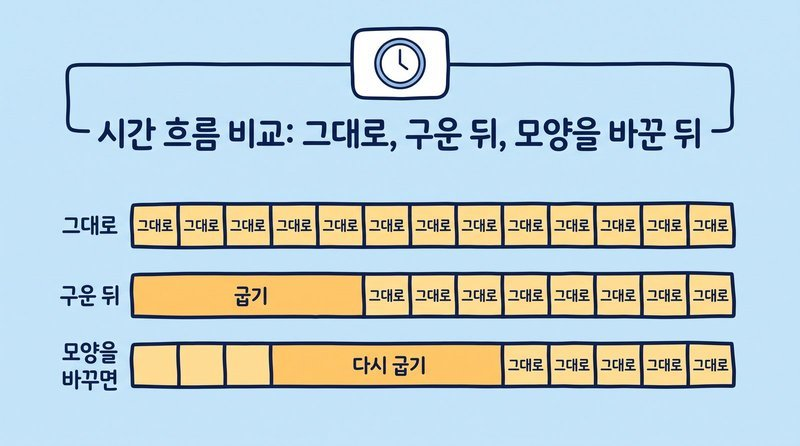

*엔진 빌드는 처음 한 번 비용을 치르고 그다음을 빠르게 하며 모양이 바뀌면 비용을 다시 치릅니다.*

CUDA 그래프의 캡처 크기와 패딩은 계산으로 봅니다(이론 노트 3.3절, 3장 심화 ‘CUDA 그래프 캡처 크기의 간격’).

In [33]:
# 실습 : 요청 n개를 실행할 캡처 그래프의 크기를 고르세요
#        캡처해 둔 크기(sizes) 가운데 n 이상인 가장 작은 값이고 그런 크기가 없으면 None(그래프 없이 실행)입니다
def pick_capture_size(n, sizes):
    ### START CODE HERE ### (sizes 가운데 n 이상인 값만 모은 목록 1줄)
    # 1) 캡처해 둔 크기 가운데 요청 n개를 담을 수 있는(n 이상인) 크기들
    bigger = [s for s in sizes if s >= n]
    ### END CODE HERE ###
    if bigger is None:
        return "빈칸"
    return min(bigger) if bigger else None


for sizes in [[1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 12, 16, 24, 32]]:
    print("캡처 크기", sizes)
    for n in [1, 3, 5, 9, 13, 17, 40]:
        s = pick_capture_size(n, sizes)
        if s == "빈칸":
            print("  아직 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
            break
        waste = "그래프 없이 실행" if s is None else f"{s}개 중 {s - n}개가 패딩 ({(s - n) / s:.0%})"
        print(f"  요청 {n:>2}개 -> {waste}")

캡처 크기 [1, 2, 4, 8, 16, 32]
  요청  1개 -> 1개 중 0개가 패딩 (0%)
  요청  3개 -> 4개 중 1개가 패딩 (25%)
  요청  5개 -> 8개 중 3개가 패딩 (38%)
  요청  9개 -> 16개 중 7개가 패딩 (44%)
  요청 13개 -> 16개 중 3개가 패딩 (19%)
  요청 17개 -> 32개 중 15개가 패딩 (47%)
  요청 40개 -> 그래프 없이 실행
캡처 크기 [1, 2, 4, 8, 12, 16, 24, 32]
  요청  1개 -> 1개 중 0개가 패딩 (0%)
  요청  3개 -> 4개 중 1개가 패딩 (25%)
  요청  5개 -> 8개 중 3개가 패딩 (38%)
  요청  9개 -> 12개 중 3개가 패딩 (25%)
  요청 13개 -> 16개 중 3개가 패딩 (19%)
  요청 17개 -> 24개 중 7개가 패딩 (29%)
  요청 40개 -> 그래프 없이 실행


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
bigger = [s for s in sizes if s >= n]
```

**캡처 크기를 촘촘히 둔 목록과 듬성듬성 둔 목록을 비교합니다.** 촘촘한 쪽은 요청 9개와 17개에서 패딩이 줄어드는 대신 캡처한 그래프가 둘(12, 24) 더 늘어 메모리와 기동 시간을 더 씁니다.

</details>

## 부록 실습 C. 1.2의 TensorRT 엔진 빌드 절차

교재 : 9.6 LLM 인프라 최적화

 RunPod에서 합니다. Step 7 트랙 2에서 만든 TensorRT-LLM 1.2 Pod에서 엔진 파일을 빌드하는 옛 절차(TensorRT 엔진 백엔드)를 따라갑니다. 1.2.1에는 이 절차가 남아 있고 1.3 사전 릴리스에서는 사라집니다(이론 노트 2장 심화 ‘1.3에서 사라지는 TensorRT 엔진 백엔드’).

In [34]:
%%writefile legacy_build.sh
#!/usr/bin/env bash
# 🖥 부록 실습 C : TensorRT-LLM 1.2 컨테이너 안에서 엔진 파일을 빌드하는 옛 절차를 따라갑니다. 1.3 에서는 이 명령들이 없습니다.
set -euo pipefail
MODEL="${D59_MODEL:-Qwen/Qwen2.5-1.5B-Instruct}"
HF_DIR="${D59_HF_DIR:-./hf_qwen15b}"
CKPT="./d59_ckpt_fp16"
ENGINE_DIR="./d59_engine_fp16"
TAG="v$(python -c 'import tensorrt_llm; print(tensorrt_llm.__version__)' 2>/dev/null | tail -1)"

huggingface-cli download "$MODEL" --local-dir "$HF_DIR"
# 변환 스크립트는 버전마다 다를 수 있어 설치된 버전과 같은 태그에서 받습니다
curl -fsSL -o convert_checkpoint.py \
  "https://raw.githubusercontent.com/NVIDIA/TensorRT-LLM/${TAG}/examples/models/core/qwen/convert_checkpoint.py"

T0=$(date +%s)
python convert_checkpoint.py --model_dir "$HF_DIR" --output_dir "$CKPT" --dtype float16
T1=$(date +%s)
trtllm-build --checkpoint_dir "$CKPT" --output_dir "$ENGINE_DIR" --gemm_plugin float16 \
  --max_batch_size 64 --max_seq_len 4096
T2=$(date +%s)
echo "변환 $((T1 - T0))초, 빌드 $((T2 - T1))초"
du -sh "$CKPT" "$ENGINE_DIR"
ls "$ENGINE_DIR"
nvidia-smi --query-gpu=name,compute_cap --format=csv,noheader | tee "$ENGINE_DIR/구운_GPU.txt"

Overwriting legacy_build.sh


In [35]:
r = subprocess.run(["bash", "-n", "legacy_build.sh"], capture_output=True, text=True)
print("legacy_build.sh 구문 :", "통과" if r.returncode == 0 else r.stderr)

legacy_build.sh 구문 : 통과


빌드한 엔진 파일로 서버를 기동할 때는 1.2.1 `trtllm-serve`의 `--backend tensorrt` 선택지를 씁니다. 소스의 선택지를 따라 적은 명령이고 GPU에서는 확인하지 못했습니다(확인 못 함).

(파드(리눅스) 터미널에서 실행합니다)

```bash
trtllm-serve ./d59_engine_fp16 --backend tensorrt --tokenizer ./hf_qwen15b --port 8593
```

**기록할 것**

- 변환 시간, 빌드 시간, 엔진 폴더의 크기  
- 받을 준비를 마칠 때까지의 시간. Step 7 트랙 2의 PyTorch 백엔드 측정 행과 비교합니다  
- 빌드할 때 정한 최대 길이(4,096토큰)보다 긴 입력을 보냈을 때의 응답  
- 같은 스크립트를 1.3 사전 릴리스 이미지에서 실행했을 때 어디서 멈추는지

## 부록 실습 D. 생성 설정 기본값의 함정 재현

부록 실습 A의 평가 하네스(`Q`, `GEN_QA`)를 씁니다. vLLM을 `--generation-config vllm` 없이 기본값으로 기동하고 같은 질문 30개를 두 번 보냅니다. 한 번은 온도만 적은 요청으로, 한 번은 GEN_QA를 모두 적은 요청으로 보냅니다.

In [ ]:
if not HAS_GPU or pkgver("vllm") == "미설치":
    print("GPU 런타임에서 vLLM을 설치한 뒤에 실행합니다")
elif "Q" not in globals() or globals().get("GEN_QA") is None:
    print("부록 실습 A의 평가 하네스를 먼저 실행합니다")
else:
    port = pick_port(PORT_BASE + 4)
    cmd = ["vllm", "serve", MODEL_ID, "--dtype", "half", "--max-model-len", "4096",
           "--gpu-memory-utilization", "0.85", "--seed", "0", "--host", "127.0.0.1", "--port", str(port)]
    proc, why, ready = start_server(cmd, port, "vllm_auto.log", timeout=1200)
    print("기본값 서버 :", why, ready)
    if proc is not None:
        log = Path("vllm_auto.log").read_text(encoding="utf-8", errors="ignore")
        w = re.search(r"Default vLLM sampling parameters have been overridden by (.+)", log)
        print("서버가 읽어 온 저장소 기본값 :", w.group(1)[:160] if w else "로그에서 찾지 못함")
        url = f"http://127.0.0.1:{port}"
        naive = Q.measure_quality(url, MODEL_ID, {"temperature": 0.0})
        full = Q.measure_quality(url, MODEL_ID, GEN_QA)
        changed = [q["id"] for q in Q.QUESTIONS if naive["answers"][q["id"]] != full["answers"][q["id"]]]
        mean_len = lambda res: sum(len(a) for a in res["answers"].values()) / len(res["answers"])
        print(f"답이 달라진 질문 {len(changed)}개 : {changed[:10]}")
        print(f"평균 답 길이 : 온도만 {mean_len(naive):.0f}자, 전부 적음 {mean_len(full):.0f}자")
        print("온도만 적은 쪽 대비 flip :", Q.count_flips(naive["correct"], full["correct"]))
        stop_server(proc)

기본값 서버 : 준비됨 61.8
서버가 읽어 온 저장소 기본값 : the model's `generation_config.json`: `{'repetition_penalty': 1.1, 'temperature': 0.7, 'top_k': 20, 'top_p': 0.8}`. If this is not intended, please relaunch vLL


**기록할 것** : 서버가 읽어 온 저장소 기본값, 답이 달라진 질문 수, 평균 답 길이.

## 부록 실습 E. 입력 길이 분포별 측정

같은 서버에 짧은 질문만 모은 파일과 긴 질문만 모은 파일을 따로 보내 첫 토큰 시간이 입력 길이에 따라 어떻게 달라지는지 측정합니다(이론 노트 5.3절).

In [ ]:
!python make_prompts.py --long-ratio 0 --out d59_short.jsonl
!python make_prompts.py --long-ratio 1 --out d59_long.jsonl

In [ ]:
if not HAS_GPU or pkgver("vllm") == "미설치":
    print("GPU 런타임에서 vLLM을 설치한 뒤에 실행합니다")
else:
    port = pick_port(PORT_BASE + 5)
    cmd = ["vllm", "serve", MODEL_ID, "--dtype", "half", "--max-model-len", "4096",
           "--gpu-memory-utilization", "0.85", "--max-num-seqs", "128", "--max-num-batched-tokens", "8192",
           "--enable-chunked-prefill", "--generation-config", "vllm", "--seed", "0",
           "--host", "127.0.0.1", "--port", str(port)]
    proc, why, ready = start_server(cmd, port, "vllm_len.log", timeout=1200)
    if proc is not None:
        for name in ["d59_short.jsonl", "d59_long.jsonl"]:
            subprocess.run([sys.executable, "bench_openai.py", "--base-url", f"http://127.0.0.1:{port}",
                            "--model", MODEL_ID, "--engine", "vllm", "--precision", "fp16", "--gpu", GPU_NAME,
                            "--prompts", name, "--concurrency", "1,4,16", "--notes", name,
                            "--out", "d59_bench_length.csv"])
        stop_server(proc)
    for r in load_bench_csv("d59_bench_length.csv"):
        print(f"{r['notes']:<16} 동시 {int(r['concurrency']):>2} 입력 평균 {r['input_tokens_mean']}토큰 "
              f"첫 토큰 p50 {r['ttft_p50_ms']} ms")

**기록할 것** : 짧은 질문과 긴 질문의 입력 토큰 평균과 첫 토큰 시간.

## 부록 실습 F. 조건 그룹별 측정표 출력

Step 6에서 만든 조건 그룹(`cond_groups`)을 동시 요청 수별 숫자 표로 출력합니다. 그래프의 점을 숫자로 읽거나 판단서에 표를 붙일 때 씁니다.

In [ ]:
def fmt(v, spec):
    """값이 없으면 같은 너비로 '-'를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)


for n, (key, by_engine) in enumerate(cond_groups.items(), 1):
    some = next(iter(by_engine.values()))[0]
    print(f"[조건 그룹 {n}] GPU {some['gpu']} / {some['precision']} / 질문 파일 {some['prompt_sha']} / 엔진 {sorted(by_engine)}")
    print(f"  {'측정(run_id)':<24} {'동시':>4} {'첫토큰p50':>9} {'첫토큰p99':>9} {'간격p50':>8} {'간격p99':>8} {'초당토큰':>9}")
    for eng, rs in sorted(by_engine.items()):
        for r in sorted(rs, key=lambda r: r["concurrency"]):
            print(f"  {eng:<24} {int(r['concurrency']):>4} {fmt(r['ttft_p50_ms'], '>9.0f')} "
                  f"{fmt(r['ttft_p99_ms'], '>9.0f')} {fmt(r['tpot_p50_ms'], '>8.1f')} {fmt(r['tpot_p99_ms'], '>8.1f')} "
                  f"{fmt(r['output_tok_s'], '>9.0f')}")
if not cond_groups:
    print("(점검을 통과한 실측 행이 없습니다. 강사 CSV를 업로드하거나 GPU 런타임에서 Step 5를 실행하세요)")

## 부록 실습 G. RunPod 기동·측정 스크립트

강사 CSV와 Step 7 트랙 2의 CSV는 RunPod Pod 안에서 이 `serve_and_bench.sh`로 만듭니다. 두 엔진에 같게 주는 값(최대 길이, 최대 요청 수, 한 스텝의 토큰 수, fp16, 청크 분할 프리필)이 스크립트 안에 모여 있습니다. 트랙 2를 하는 팀은 이 셀을 실행해 파일을 만든 뒤 Pod에 업로드합니다.

In [ ]:
%%writefile serve_and_bench.sh
#!/usr/bin/env bash
# 🖥 RunPod Pod 안에서 엔진 하나를 기동해 측정하고 종료합니다. 사용법은 트랙 2의 1·3번
# make_prompts.py, bench_openai.py 가 같은 폴더에 있어야 하고 d59_quality.py(부록 실습 A)가 있으면 품질도 측정합니다.
set -euo pipefail

ENGINE="${ENGINE:?ENGINE=vllm 또는 ENGINE=tensorrt-llm 으로 실행하세요}"
MODEL="${D59_MODEL:-Qwen/Qwen2.5-1.5B-Instruct}"
REVISION="${D59_REVISION:-}"                 # 모델 저장소의 커밋
PORT="${D59_PORT:-8591}"
CONC="${D59_CONC:-1,2,4,8,16,32,64}"
OUT_TOKENS="${D59_OUTPUT_TOKENS:-128}"
OUT="${D59_OUT:-d59_bench_instructor.csv}"
QA_OUT="${D59_QA_OUT:-d59_quality_instructor.csv}"
KV_TOKENS="${D59_KV_TOKENS:-}"               # TensorRT-LLM 의 KV 캐시를 vLLM 에 맞출 때
GEN='{"temperature": 0.0, "top_p": 1.0, "repetition_penalty": 1.0, "seed": 0}'
GPU="$(nvidia-smi --query-gpu=name --format=csv,noheader | head -1)"
CC="$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader | head -1)"
LOG="server_${ENGINE}.log"

[ -f d59_prompts.jsonl ] || python make_prompts.py

# 두 엔진에 같게 주는 값 : 최대 길이 4096, 한 번에 받을 요청 128, 한 스텝의 토큰 8192, fp16, 청크 분할 프리필 켬
if [ "$ENGINE" = "vllm" ]; then
  VER="$(python -c 'import vllm; print(vllm.__version__)')"
  CMD=(vllm serve "$MODEL" --dtype half --max-model-len 4096 --gpu-memory-utilization 0.85
       --max-num-seqs 128 --max-num-batched-tokens 8192 --enable-chunked-prefill
       --generation-config vllm --seed 0 --host 127.0.0.1 --port "$PORT")
  [ -n "$REVISION" ] && CMD+=(--revision "$REVISION")
elif [ "$ENGINE" = "tensorrt-llm" ]; then
  VER="$(python -c 'import tensorrt_llm; print(tensorrt_llm.__version__)' 2>/dev/null | tail -1)"
  {
    echo "dtype: float16"
    echo "enable_chunked_prefill: true"
    echo "enable_iter_perf_stats: true"
    echo "kv_cache_config:"
    echo "  free_gpu_memory_fraction: 0.85"
    [ -n "$KV_TOKENS" ] && echo "  max_tokens: $KV_TOKENS"
  } > d59_trtllm.yml
  CMD=(trtllm-serve "$MODEL" --host 127.0.0.1 --port "$PORT" --max_seq_len 4096
       --max_batch_size 128 --max_num_tokens 8192 --config d59_trtllm.yml)
  [ -n "$REVISION" ] && CMD+=(--revision "$REVISION")
else
  echo "ENGINE 은 vllm 또는 tensorrt-llm 입니다 : $ENGINE"; exit 2
fi

echo "[$ENGINE $VER] ${CMD[*]}"
T0=$(date +%s.%N)
"${CMD[@]}" > "$LOG" 2>&1 &
PID=$!
trap 'kill $PID 2>/dev/null || true' EXIT

READY=""
for _ in $(seq 1 1800); do
  if curl -sf "http://127.0.0.1:$PORT/health" > /dev/null; then
    READY=$(python -c "print(round($(date +%s.%N) - $T0, 1))"); break
  fi
  kill -0 $PID 2>/dev/null || { echo "서버가 멈췄습니다. $LOG 끝부분 :"; tail -20 "$LOG"; exit 1; }
  sleep 1
done
[ -n "$READY" ] || { echo "30분 안에 준비되지 않았습니다"; exit 1; }
echo "받을 준비를 마칠 때까지 ${READY}초"

# TensorRT-LLM 의 /metrics 는 요청이 하나 있어야 값이 찹니다
curl -sf "http://127.0.0.1:$PORT/v1/chat/completions" -H "Content-Type: application/json" \
  -d "{\"model\": \"$MODEL\", \"messages\": [{\"role\": \"user\", \"content\": \"안녕하세요\"}], \"max_tokens\": 8}" > /dev/null

if [ "$ENGINE" = "vllm" ]; then
  KV=$(grep -o "GPU KV cache size: [0-9,]* tokens" "$LOG" | head -1 | tr -dc '0-9')
else
  KV=$(python - "$PORT" <<'PY'
import json, sys, urllib.request
def walk(o):
    for k, v in (o.items() if isinstance(o, dict) else enumerate(o) if isinstance(o, list) else []):
        yield str(k).lower().replace("_", ""), v
        yield from walk(v)
try:
    flat = dict(walk(json.load(urllib.request.urlopen(f"http://127.0.0.1:{sys.argv[1]}/metrics", timeout=10))))
    b, t = flat.get("maxnumblocks"), flat.get("tokensperblock")
    print(int(b * t) if b and t else "")
except Exception:
    print("")
PY
)
fi
echo "KV 캐시 : ${KV:-확인 못 함} 토큰"

python bench_openai.py --base-url "http://127.0.0.1:$PORT" --model "$MODEL" --engine "$ENGINE" \
  --engine-version "$VER" --server-cmd "${CMD[*]}" --model-revision "$REVISION" --precision fp16 \
  --gpu "$GPU" --gpu-cc "$CC" --kv-cache-tokens "$KV" --ready-s "$READY" \
  --prompts d59_prompts.jsonl --concurrency "$CONC" --output-tokens "$OUT_TOKENS" --notes "chunked_prefill=on" --out "$OUT"
if [ -f d59_quality.py ]; then
  python d59_quality.py --base-url "http://127.0.0.1:$PORT" --model "$MODEL" --engine "$ENGINE" \
    --engine-version "$VER" --precision fp16 --gpu "$GPU" --gen-json "$GEN" --out "$QA_OUT"
  echo "끝 : $OUT, $QA_OUT"
else
  echo "d59_quality.py 가 없어 품질 측정은 건너뜁니다(부록 실습 A). 끝 : $OUT"
fi

In [ ]:
# 코랩에서는 구문만 확인합니다. 실제로는 RunPod 파드 안에서 실행합니다
r = subprocess.run(["bash", "-n", "serve_and_bench.sh"], capture_output=True, text=True)
print("serve_and_bench.sh 구문 :", "통과" if r.returncode == 0 else r.stderr)

In [ ]:
# 두 Pod에서 받은 CSV를 하나로 합칩니다. 열(첫 줄)이 같은 파일만 합칩니다
parts = [Path(p).read_text(encoding="utf-8").splitlines()
         for p in ["d59_bench_vllm_pod.csv", "d59_bench_trtllm_pod.csv"] if Path(p).exists()]
if parts and all(p[0] == parts[0][0] for p in parts):
    lines = parts[0] + [l for p in parts[1:] for l in p[1:]]
    Path("d59_bench_merged.csv").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print(f"합친 행 {len(lines) - 1}개 -> d59_bench_merged.csv")
else:
    print("합칠 파일이 없거나 두 파일의 열이 다릅니다")

## 부록 실습 H. 점검 함수 단위 테스트

Step 2의 빈칸을 채운 뒤 조건 열만 다르게 만든 행 셋으로 점검 함수를 확인합니다.

In [ ]:
# 검산용으로 직접 정한 값입니다. 실제 엔진 성능을 나타내는 행이 아닙니다.
# 조건 열만 다르게 만든 테스트용 행입니다. 결과 열은 비워 두었습니다
base_cond = {"source": "실측", "model": MODEL_ID, "model_revision": "fixture-only-commit", "precision": "fp16", "gpu": "NVIDIA L4",
             "prompt_sha": "test", "prompt_offset": 0, "output_tokens": 128, "ignore_eos": "True",
             "gen_params": "{}", "warmup": 4, "num_requests": 16, "tool": "bench_openai.py d59-1",
             "concurrency": 4, "repeats": 0, "errors": 0, "kv_cache_tokens": None, "output_tok_s": 1.0}
test_rows = [dict(base_cond, engine="vllm"),
             dict(base_cond, engine="tensorrt-llm", precision="fp8"),
             dict(base_cond, engine="tensorrt-llm", concurrency=8, warmup=0)]
problems, ok_idx = fairness_report(test_rows, MUST_MATCH)
if problems is not None:
    print("\n".join(problems) or "문제 없음")
    print("문제가 없는 행 :", sorted(ok_idx))
    print("같은 조건으로 비교할 수 있는 엔진 :", comparable_sets(test_rows, ok_idx, MUST_MATCH) or "없음")

정답을 채웠다면 예열이 0이고 요청이 모자란 행 2를 빼고 행 0과 행 1은 정밀도가 달라 같은 조건으로 비교할 수 없다고 알려야 합니다.